# Detecção de fraude em cartão de crédito

Projeto de classificação binária para identificar transações fraudulentas em cartões de crédito europeus (setembro de 2013).

**Por que este problema é difícil:** de cada 1.000 transações, menos de 2 são fraude. Um modelo que responde "normal" para tudo acerta 99,8% das vezes e não pega nenhuma fraude. Por isso a acurácia é deixada de lado e a avaliação olha para a **classe de fraude**:

- **Recall (sensibilidade):** de todas as fraudes reais, quantas o modelo pegou. É a métrica principal, porque cada fraude perdida é prejuízo direto.
- **Precisão:** de todos os alertas que o modelo levantou, quantos eram fraude de verdade. Precisão baixa significa clientes bloqueados sem motivo e equipe de análise sobrecarregada.
- **F1:** média harmônica entre recall e precisão, útil para comparar modelos com um único número.
- **Average precision (AP):** área sob a curva de precisão e recall, que resume o modelo em todos os limiares e não depende de um corte específico.

**Roteiro do notebook**

1. Explorar os dados
2. Preparar (transformação logarítmica, divisão estratificada e padronização)
3. Treinar Regressão Logística, Random Forest e XGBoost
4. Avaliar cada modelo e comparar
5. Ajustar: Pipeline, limiar de decisão, GridSearchCV e as evoluções (reamostragem, Random Forest com ajuste de limiar e variáveis de tempo)
6. Explicar o melhor modelo de árvore com importância das variáveis e SHAP
7. Comparação final de todos os modelos e conclusões

## Configuração

A célula abaixo só instala alguma biblioteca se ela não estiver disponível no ambiente (útil no Google Colab, onde `imbalanced-learn` ou `shap` podem faltar). Em um ambiente com o `requirements.txt` instalado, ela não faz nada.

In [1]:
import importlib.util
import subprocess
import sys

pacotes = {'xgboost': 'xgboost', 'imblearn': 'imbalanced-learn', 'shap': 'shap'}
faltando = [nome_pip for modulo, nome_pip in pacotes.items() if importlib.util.find_spec(modulo) is None]
if faltando:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltando])
print('Instalados agora: ' + ', '.join(faltando) if faltando else 'Todas as bibliotecas já estão disponíveis.')

Todas as bibliotecas já estão disponíveis.


In [2]:
import time
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message='IProgress not found')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
import xgboost
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

SEMENTE = 42
FUNDO = '#fcfcfb'
TINTA = '#0b0b0b'
TINTA_SECUNDARIA = '#52514e'
TINTA_SUAVE = '#898781'
GRADE = '#e1e0d9'
EIXO = '#c3c2b7'
AZUL, LARANJA, AQUA, AMARELO, MAGENTA, VERDE, VIOLETA, VERMELHO = (
    '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948'
)
CORES_CLASSE = {'Normal': AZUL, 'Fraude': LARANJA}

plt.rcParams.update({
    'figure.dpi': 100,
    'figure.facecolor': FUNDO,
    'axes.facecolor': FUNDO,
    'savefig.facecolor': FUNDO,
    'axes.edgecolor': EIXO,
    'axes.labelcolor': TINTA_SECUNDARIA,
    'axes.titlecolor': TINTA,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': GRADE,
    'grid.linewidth': 0.7,
    'xtick.color': TINTA_SECUNDARIA,
    'ytick.color': TINTA_SECUNDARIA,
    'lines.linewidth': 2,
    'legend.frameon': False,
    'font.size': 10,
})
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)


def br(numero, casas=2):
    return f'{numero:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


print(f'pandas {pd.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | shap {shap.__version__}')

pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1 | shap 0.54.1


## 1. Explorar os dados

O arquivo tem cerca de 150 MB e é lido **direto da URL** com `pd.read_csv`, sem ser salvo no repositório.

- `Time`: segundos desde a primeira transação da base (cobre dois dias).
- `Amount`: valor da transação.
- `V1` a `V28`: componentes de PCA. As variáveis originais foram anonimizadas por confidencialidade, então essas colunas não têm nome de negócio.
- `Class`: variável resposta (1 = fraude, 0 = normal).

In [3]:
URL_DADOS = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'

inicio = time.time()
df = pd.read_csv(URL_DADOS)
print(f'{br(df.shape[0], 0)} linhas e {df.shape[1]} colunas carregadas em {time.time() - inicio:.1f} s')

284.807 linhas e 31 colunas carregadas em 15.7 s


In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


Não há valores ausentes e todas as colunas são numéricas. As variáveis `V1` a `V28` já estão centradas em zero (consequência do PCA), enquanto `Time` e `Amount` estão em escalas bem diferentes. `Amount` tem média perto de 88, mas máximo acima de 25 mil: a distribuição é muito assimétrica.

### Proporção de fraudes

In [7]:
df['Class'].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

In [8]:
nomes_classe = {0: 'Normal', 1: 'Fraude'}
contagem = df['Class'].value_counts().rename(index=nomes_classe)
proporcao = df['Class'].value_counts(normalize=True).rename(index=nomes_classe)
pd.DataFrame({'Transações': contagem, 'Proporção': proporcao.round(5), 'Percentual (%)': (proporcao * 100).round(3)})

,Transações,Proporção,Percentual (%)
Class,,,
Normal,284315,0.99827,99.827
Fraude,492,0.00173,0.173


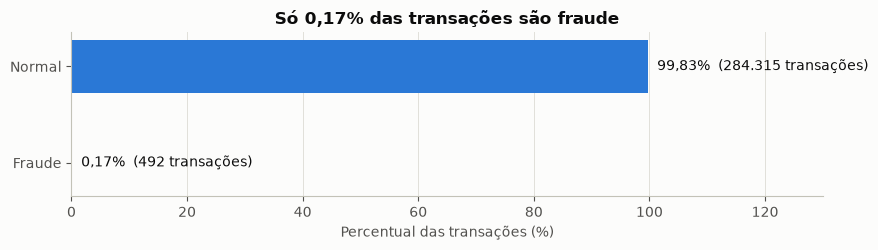

In [9]:
fig, ax = plt.subplots(figsize=(9, 2.6))
classes = ['Normal', 'Fraude']
percentuais = proporcao.loc[classes] * 100
barras = ax.barh(classes, percentuais, color=[CORES_CLASSE[c] for c in classes], height=0.55)
for barra, classe in zip(barras, classes):
    rotulo = f'{br(percentuais[classe], 2)}%  ({br(contagem[classe], 0)} transações)'
    ax.text(barra.get_width() + 1.5, barra.get_y() + barra.get_height() / 2, rotulo, va='center', color=TINTA)
ax.set_xlim(0, 130)
ax.invert_yaxis()
ax.set_xlabel('Percentual das transações (%)')
ax.set_title('Só 0,17% das transações são fraude')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

A barra de fraude quase não aparece: são **492 fraudes em 284.807 transações** (0,17%). Esse é o ponto central do projeto:

- Um classificador que chuta "normal" sempre teria **99,83% de acurácia** e **recall zero**.
- Qualquer divisão de treino e teste precisa manter essa proporção (estratificação), senão o teste pode ficar com pouquíssimas fraudes.
- Os modelos precisam de algum mecanismo para dar peso à classe rara (pesos de classe, `scale_pos_weight` ou reamostragem).

### Valor e horário das transações por classe

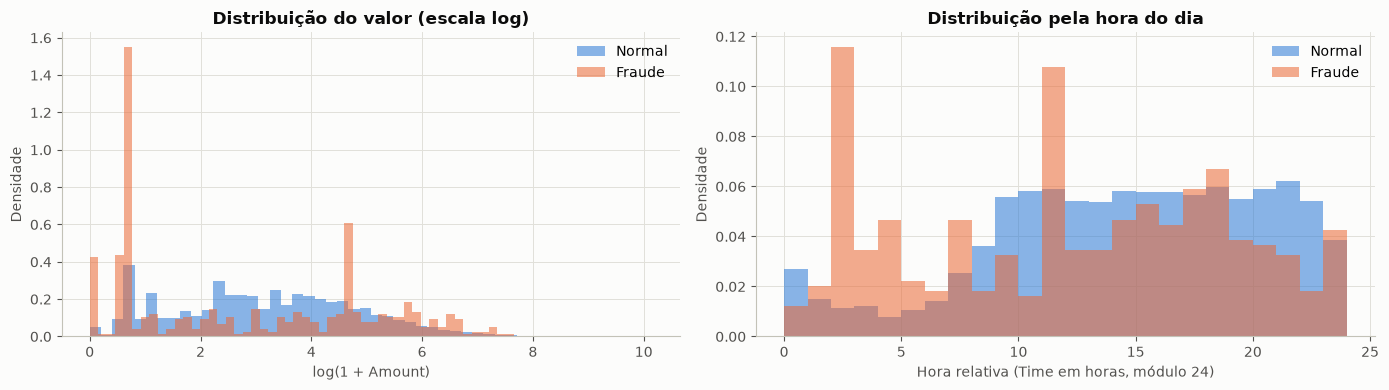

Horas com maior taxa de fraude (%):
Hora_relativa
2.0    1.713
4.0    1.041
3.0    0.487
5.0    0.368
7.0    0.318


In [10]:
df['Hora_relativa'] = (df['Time'] // 3600) % 24

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
for classe, nome in nomes_classe.items():
    dados = df[df['Class'] == classe]
    eixos[0].hist(np.log1p(dados['Amount']), bins=50, density=True, alpha=0.55, color=CORES_CLASSE[nome], label=nome)
    eixos[1].hist(dados['Hora_relativa'], bins=np.arange(25), density=True, alpha=0.55, color=CORES_CLASSE[nome], label=nome)
eixos[0].set_title('Distribuição do valor (escala log)')
eixos[0].set_xlabel('log(1 + Amount)')
eixos[0].set_ylabel('Densidade')
eixos[1].set_title('Distribuição pela hora do dia')
eixos[1].set_xlabel('Hora relativa (Time em horas, módulo 24)')
eixos[1].set_ylabel('Densidade')
for ax in eixos:
    ax.legend()
plt.tight_layout()
plt.show()

taxa_por_hora = df.groupby('Hora_relativa')['Class'].mean() * 100
print('Horas com maior taxa de fraude (%):')
print(taxa_por_hora.sort_values(ascending=False).head(5).round(3).to_string())
df = df.drop(columns='Hora_relativa')

Dois sinais aparecem antes de qualquer modelo:

- **Valor:** as fraudes se concentram em valores muito baixos (testes de cartão) e também se espalham por valores médios. Na escala log as duas distribuições ficam comparáveis.
- **Horário:** as transações normais caem muito durante a madrugada, mas as fraudes não caem na mesma proporção. Nas horas de menor movimento, a taxa de fraude chega a ser 10 vezes maior que a média. Esse padrão motiva as variáveis de tempo criadas na seção 5.

## 2. Preparar os dados

Três passos:

1. **`Amount_log = log(1 + Amount)`** para reduzir a assimetria do valor. O `log1p` aceita valor zero sem erro.
2. **Divisão treino e teste estratificada** (`stratify=y`, 70/30, `random_state` fixo) para manter a mesma proporção de fraudes nos dois conjuntos.
3. **Padronização com `StandardScaler`**, ajustada **somente no treino** e aplicada ao teste. Se o padronizador fosse ajustado na base inteira, média e desvio do teste vazariam para o treino.

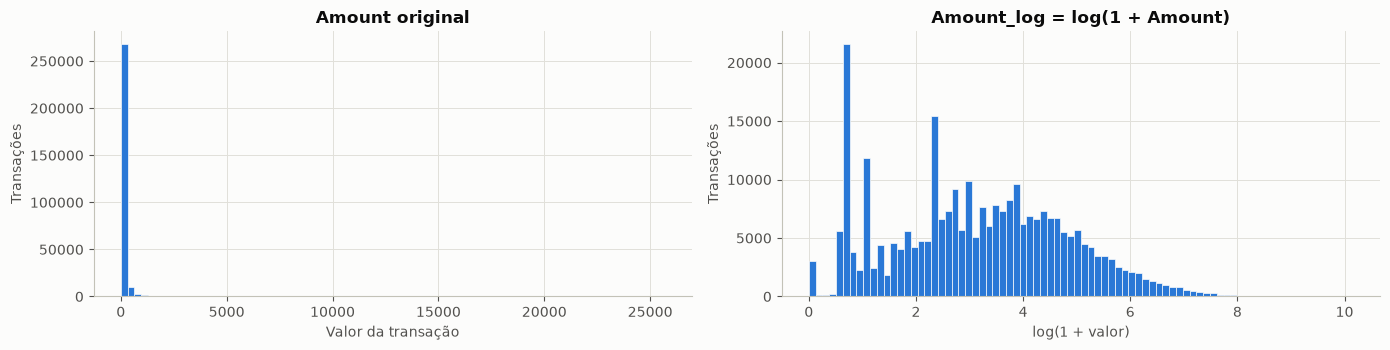

Assimetria de Amount: 16.98 | Assimetria de Amount_log: 0.16


In [11]:
df['Amount_log'] = np.log1p(df['Amount'])

fig, eixos = plt.subplots(1, 2, figsize=(14, 3.6))
eixos[0].hist(df['Amount'], bins=80, color=AZUL, edgecolor=FUNDO, linewidth=0.5)
eixos[0].set_title('Amount original')
eixos[0].set_xlabel('Valor da transação')
eixos[0].set_ylabel('Transações')
eixos[1].hist(df['Amount_log'], bins=80, color=AZUL, edgecolor=FUNDO, linewidth=0.5)
eixos[1].set_title('Amount_log = log(1 + Amount)')
eixos[1].set_xlabel('log(1 + valor)')
eixos[1].set_ylabel('Transações')
plt.tight_layout()
plt.show()

print(f"Assimetria de Amount: {df['Amount'].skew():.2f} | Assimetria de Amount_log: {df['Amount_log'].skew():.2f}")

In [12]:
COLUNAS_V = [f'V{i}' for i in range(1, 29)]
VARIAVEIS = ['Time'] + COLUNAS_V + ['Amount_log']

X = df[VARIAVEIS]
y = df['Class']

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEMENTE
)

pd.DataFrame({
    'Transações': [len(y), len(y_treino), len(y_teste)],
    'Fraudes': [y.sum(), y_treino.sum(), y_teste.sum()],
    'Fraudes (%)': [y.mean() * 100, y_treino.mean() * 100, y_teste.mean() * 100],
}, index=['Base completa', 'Treino', 'Teste']).round(4)

,Transações,Fraudes,Fraudes (%)
Base completa,284807,492,0.1727
Treino,199364,344,0.1725
Teste,85443,148,0.1732


A proporção de fraudes é praticamente idêntica na base completa, no treino e no teste (cerca de 0,173%). O teste guarda 148 fraudes, então cada fraude vale cerca de 0,7 ponto percentual de recall. Diferenças de um ou dois pontos entre modelos devem ser lidas com cautela.

In [13]:
padronizador = StandardScaler()
X_treino_pad = pd.DataFrame(padronizador.fit_transform(X_treino), columns=VARIAVEIS, index=X_treino.index)
X_teste_pad = pd.DataFrame(padronizador.transform(X_teste), columns=VARIAVEIS, index=X_teste.index)

pd.DataFrame({
    'Média no treino': X_treino_pad[['Time', 'Amount_log', 'V1', 'V14']].mean(),
    'Desvio no treino': X_treino_pad[['Time', 'Amount_log', 'V1', 'V14']].std(),
    'Média no teste': X_teste_pad[['Time', 'Amount_log', 'V1', 'V14']].mean(),
    'Desvio no teste': X_teste_pad[['Time', 'Amount_log', 'V1', 'V14']].std(),
}).round(3)

,Média no treino,Desvio no treino,Média no teste,Desvio no teste
Time,-0.0,1.0,-0.006,1.000
Amount_log,-0.0,1.0,-0.004,1.001
V1,0.0,1.0,0.002,0.988
V14,0.0,1.0,0.003,0.997


No treino as variáveis ficam com média 0 e desvio 1. No teste ficam muito próximas disso, mas não exatamente, porque o teste foi transformado com os parâmetros aprendidos no treino. É assim que deve ser: o teste simula dados novos.

## 3. Treinar e comparar modelos

| Modelo | Como lida com o desbalanceamento |
|---|---|
| Regressão Logística (baseline) | Não lida. Serve de referência para medir o ganho dos outros modelos. |
| Random Forest | `class_weight='balanced'`: o peso de cada classe é inversamente proporcional à sua frequência, então cada fraude pesa cerca de 578 vezes mais que uma transação normal na construção das árvores. |
| XGBoost | `scale_pos_weight` = normais / fraudes no treino, que multiplica o gradiente da classe positiva. |

In [14]:
peso_fraude = (y_treino == 0).sum() / (y_treino == 1).sum()
print(f'scale_pos_weight = {peso_fraude:.1f} transações normais para cada fraude no treino')


def criar_xgboost(**parametros):
    configuracao = dict(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='aucpr',
        tree_method='hist',
        random_state=SEMENTE,
        n_jobs=-1,
    )
    configuracao.update(parametros)
    return XGBClassifier(**configuracao)


def criar_random_forest(**parametros):
    configuracao = dict(n_estimators=200, class_weight='balanced', n_jobs=-1, random_state=SEMENTE)
    configuracao.update(parametros)
    return RandomForestClassifier(**configuracao)


modelos = {
    'Regressão Logística': LogisticRegression(max_iter=1000, random_state=SEMENTE),
    'Random Forest': criar_random_forest(),
    'XGBoost': criar_xgboost(scale_pos_weight=peso_fraude),
}

probabilidades = {}
for nome, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_treino_pad, y_treino)
    probabilidades[nome] = modelo.predict_proba(X_teste_pad)[:, 1]
    print(f'{nome}: treinado em {time.time() - inicio:.1f} s')

scale_pos_weight = 578.5 transações normais para cada fraude no treino


Regressão Logística: treinado em 0.2 s


Random Forest: treinado em 14.7 s


XGBoost: treinado em 3.1 s


## 4. Avaliar cada modelo

Para cada modelo:

- **`classification_report`** com precisão, recall e F1 das duas classes (o que interessa é a linha `Fraude`).
- **Matriz de confusão** com o limiar padrão de 0,5: quantas fraudes foram pegas, quantas passaram e quantos alarmes falsos surgiram.
- **Curva ROC com AUC.** Com classes tão desbalanceadas a ROC tende a parecer otimista, porque a taxa de falsos positivos é dividida por mais de 85 mil normais do teste.
- **Curva de precisão e recall com average precision.** É a curva mais informativa aqui. A linha tracejada é a precisão de um modelo aleatório (0,17%).

A função `registrar` guarda as métricas de cada modelo e variação para a tabela final.

In [15]:
comparacao = []


def metricas_fraude(y_real, proba, limiar=0.5):
    previsto = (proba >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_real, previsto).ravel()
    return {
        'Recall': recall_score(y_real, previsto),
        'Precisão': precision_score(y_real, previsto, zero_division=0),
        'F1': f1_score(y_real, previsto),
        'ROC AUC': auc(*roc_curve(y_real, proba)[:2]),
        'Average precision': average_precision_score(y_real, proba),
        'Fraudes detectadas': int(vp),
        'Fraudes perdidas': int(fn),
        'Alarmes falsos': int(fp),
    }


def registrar(modelo, variacao, y_real, proba, limiar=0.5):
    linha = {'Modelo': modelo, 'Variação': variacao, 'Limiar': limiar}
    linha.update(metricas_fraude(y_real, proba, limiar))
    comparacao.append(linha)
    return linha


def avaliar(nome, y_real, proba, limiar=0.5, cor=AZUL):
    previsto = (proba >= limiar).astype(int)
    print(f'{nome} (limiar {br(limiar, 2)})\n')
    print(classification_report(y_real, previsto, target_names=['Normal', 'Fraude'], digits=3))

    fig, eixos = plt.subplots(1, 3, figsize=(16, 4.4))
    ConfusionMatrixDisplay.from_predictions(
        y_real, previsto, display_labels=['Normal', 'Fraude'], cmap='Blues', colorbar=False,
        values_format='d', ax=eixos[0]
    )
    eixos[0].set_title('Matriz de confusão')
    eixos[0].set_xlabel('Previsto')
    eixos[0].set_ylabel('Real')
    eixos[0].grid(False)

    taxa_fp, taxa_vp, _ = roc_curve(y_real, proba)
    eixos[1].plot(taxa_fp, taxa_vp, color=cor, label=f'AUC = {auc(taxa_fp, taxa_vp):.4f}')
    eixos[1].plot([0, 1], [0, 1], linestyle='--', color=TINTA_SUAVE, linewidth=1, label='Aleatório')
    eixos[1].set_title('Curva ROC')
    eixos[1].set_xlabel('Taxa de falsos positivos')
    eixos[1].set_ylabel('Taxa de verdadeiros positivos (recall)')
    eixos[1].legend(loc='lower right')

    precisao, recall, _ = precision_recall_curve(y_real, proba)
    ap = average_precision_score(y_real, proba)
    eixos[2].plot(recall, precisao, color=cor, drawstyle='steps-post', label=f'AP = {ap:.4f}')
    eixos[2].axhline(y_real.mean(), linestyle='--', color=TINTA_SUAVE, linewidth=1, label='Aleatório')
    eixos[2].set_title('Curva de precisão e recall')
    eixos[2].set_xlabel('Recall')
    eixos[2].set_ylabel('Precisão')
    eixos[2].set_ylim(0, 1.03)
    eixos[2].legend(loc='lower left')

    fig.suptitle(nome, fontweight='bold', color=TINTA)
    plt.tight_layout()
    plt.show()

Regressão Logística (limiar 0,50)

              precision    recall  f1-score   support

      Normal      0.999     1.000     1.000     85295
      Fraude      0.860     0.622     0.722       148

    accuracy                          0.999     85443
   macro avg      0.930     0.811     0.861     85443
weighted avg      0.999     0.999     0.999     85443



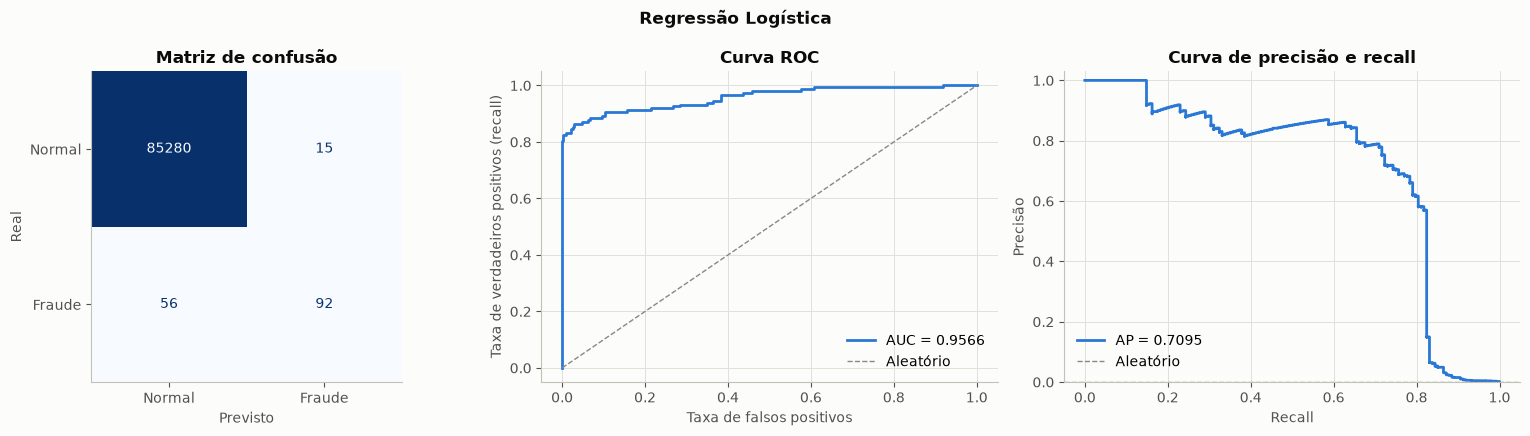

In [16]:
avaliar('Regressão Logística', y_teste, probabilidades['Regressão Logística'], cor=AZUL)

Random Forest (class_weight balanced) (limiar 0,50)

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     85295
      Fraude      0.910     0.750     0.822       148

    accuracy                          0.999     85443
   macro avg      0.955     0.875     0.911     85443
weighted avg      0.999     0.999     0.999     85443



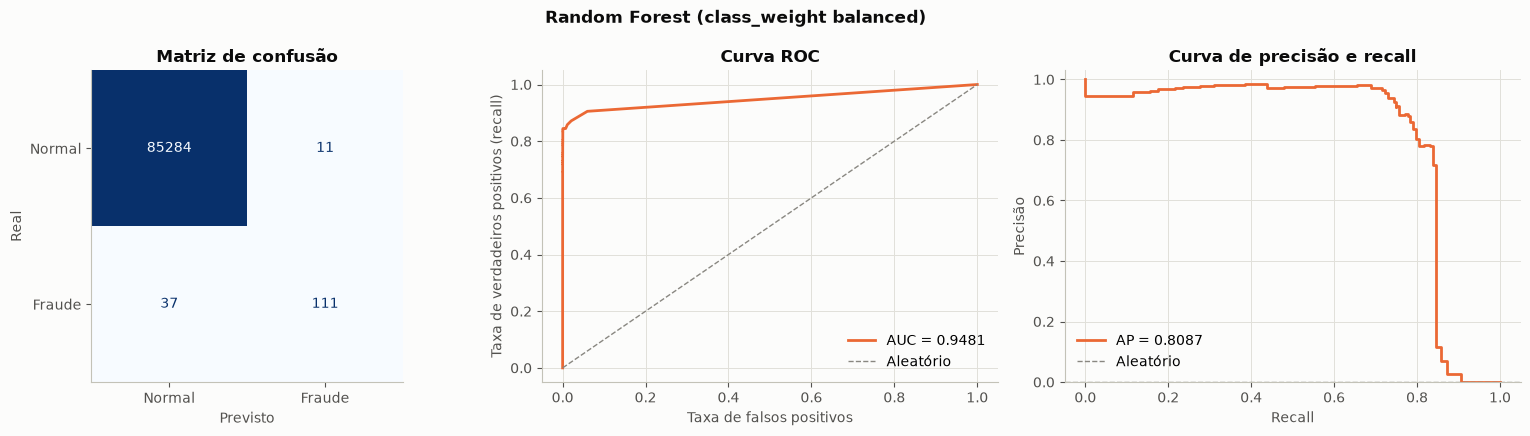

In [17]:
avaliar('Random Forest (class_weight balanced)', y_teste, probabilidades['Random Forest'], cor=LARANJA)

XGBoost (scale_pos_weight) (limiar 0,50)

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     85295
      Fraude      0.886     0.791     0.836       148

    accuracy                          0.999     85443
   macro avg      0.943     0.895     0.918     85443
weighted avg      0.999     0.999     0.999     85443



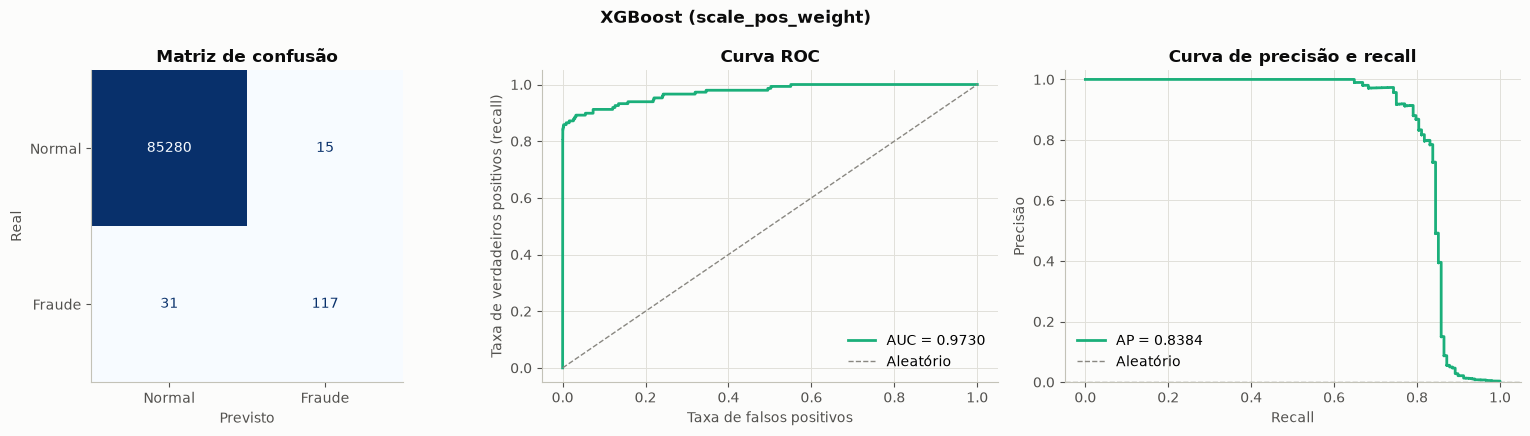

In [18]:
avaliar('XGBoost (scale_pos_weight)', y_teste, probabilidades['XGBoost'], cor=AQUA)

### Comparação dos três modelos

In [19]:
variacoes_base = {
    'Regressão Logística': 'Baseline, sem tratamento do desbalanceamento',
    'Random Forest': "class_weight='balanced'",
    'XGBoost': 'scale_pos_weight',
}
for nome, variacao in variacoes_base.items():
    registrar(nome, variacao, y_teste, probabilidades[nome])

tabela_modelos = pd.DataFrame(comparacao).set_index('Modelo').drop(columns=['Variação', 'Limiar'])
tabela_modelos.round(3)

,Recall,Precisão,F1,ROC AUC,Average precision,Fraudes detectadas,Fraudes perdidas,Alarmes falsos
Modelo,,,,,,,,
Regressão Logística,0.622,0.860,0.722,0.957,0.710,92,56,15
Random Forest,0.750,0.910,0.822,0.948,0.809,111,37,11
XGBoost,0.791,0.886,0.836,0.973,0.838,117,31,15


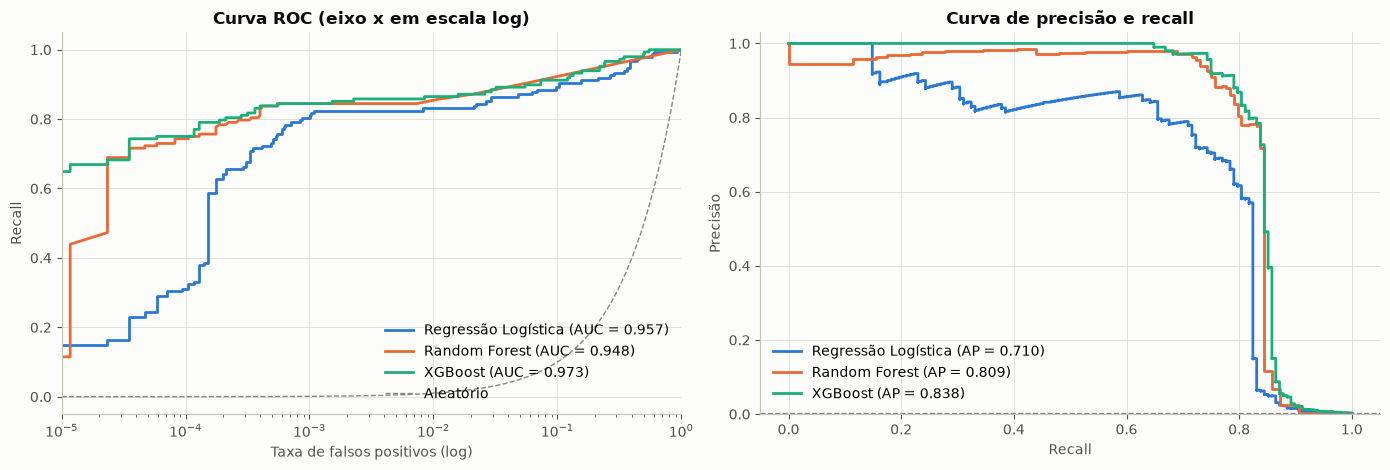

In [20]:
cores_modelos = {'Regressão Logística': AZUL, 'Random Forest': LARANJA, 'XGBoost': AQUA}

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8))
for nome, proba in probabilidades.items():
    taxa_fp, taxa_vp, _ = roc_curve(y_teste, proba)
    eixos[0].plot(taxa_fp, taxa_vp, color=cores_modelos[nome], label=f'{nome} (AUC = {auc(taxa_fp, taxa_vp):.3f})')
    precisao, recall, _ = precision_recall_curve(y_teste, proba)
    eixos[1].plot(recall, precisao, color=cores_modelos[nome], drawstyle='steps-post',
                  label=f'{nome} (AP = {average_precision_score(y_teste, proba):.3f})')
diagonal = np.logspace(-5, 0, 200)
eixos[0].plot(diagonal, diagonal, linestyle='--', color=TINTA_SUAVE, linewidth=1, label='Aleatório')
eixos[0].set_xscale('log')
eixos[0].set_xlim(1e-5, 1)
eixos[0].set_title('Curva ROC (eixo x em escala log)')
eixos[0].set_xlabel('Taxa de falsos positivos (log)')
eixos[0].set_ylabel('Recall')
eixos[0].legend(loc='lower right')
eixos[1].axhline(y_teste.mean(), linestyle='--', color=TINTA_SUAVE, linewidth=1)
eixos[1].set_title('Curva de precisão e recall')
eixos[1].set_xlabel('Recall')
eixos[1].set_ylabel('Precisão')
eixos[1].set_ylim(0, 1.03)
eixos[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

**Leitura dos resultados (limiar 0,5):**

- Os três modelos têm **99,9% de acurácia** no teste, e mesmo assim a Regressão Logística deixa passar 56 das 148 fraudes (recall 0,622). É exatamente o caso em que a acurácia esconde o problema.
- O **XGBoost** é o melhor nas duas métricas que não dependem de limiar (ROC AUC 0,973 e average precision 0,838) e tem o maior recall: pega 117 fraudes (recall 0,791) com 15 alarmes falsos (precisão 0,886).
- O **Random Forest** é o mais conservador: menos alarmes falsos (11, precisão 0,910), mas perde mais fraudes (recall 0,750).
- A ROC AUC da Regressão Logística (0,957) é até maior que a do Random Forest (0,948), mas a average precision é bem menor (0,710 contra 0,809). É por isso que a curva de precisão e recall é a referência em bases desbalanceadas: na ROC os falsos positivos são diluídos entre 85 mil transações normais e todos os modelos parecem bons. No gráfico da ROC com eixo x em escala log aparece a diferença real: perto de 0,01% de falsos positivos (cerca de 9 alarmes falsos no teste), a Regressão Logística detecta bem menos fraudes que os modelos de árvore.

Nenhum modelo passa de 0,8 de recall com o limiar padrão. A seção 5 trabalha esse ponto.

## 5. Ajustar

### 5.1 Pipeline: padronização + modelo

Até aqui a padronização foi feita "na mão". O `Pipeline` junta `StandardScaler` e modelo num único objeto, o que traz duas vantagens:

- **Sem vazamento na validação cruzada:** em cada fold o padronizador é ajustado só na parte de treino daquele fold.
- **Um objeto só para produção:** recebe os dados brutos e devolve a probabilidade, sem risco de esquecer um passo.

O pipeline recebe `X_treino` **sem padronização**.

In [21]:
pipeline_lr = Pipeline([
    ('padronizacao', StandardScaler()),
    ('modelo', LogisticRegression(max_iter=1000, random_state=SEMENTE)),
])
pipeline_lr.fit(X_treino, y_treino)
proba_pipeline_lr = pipeline_lr.predict_proba(X_teste)[:, 1]

print(pipeline_lr)
diferenca = np.abs(proba_pipeline_lr - probabilidades['Regressão Logística']).max()
print(f'\nMaior diferença de probabilidade para a Regressão Logística da seção 3: {diferenca:.2e}')

Pipeline(steps=[('padronizacao', StandardScaler()),
                ('modelo', LogisticRegression(max_iter=1000, random_state=42))])

Maior diferença de probabilidade para a Regressão Logística da seção 3: 0.00e+00


O resultado é o mesmo da seção 3 (a diferença é só erro numérico). O ganho do pipeline não está no número, e sim na garantia de que a padronização nunca vê dados de validação ou teste.

### 5.2 Limiar de decisão: 0,5 contra 0,3

`predict()` classifica como fraude quando a probabilidade é maior ou igual a 0,5. Esse corte não tem nada de especial: num problema em que perder uma fraude custa mais que um alarme falso, faz sentido baixar o limiar. Com 0,3 o modelo passa a marcar como fraude transações sobre as quais tem menos certeza: o recall sobe e a precisão cai.

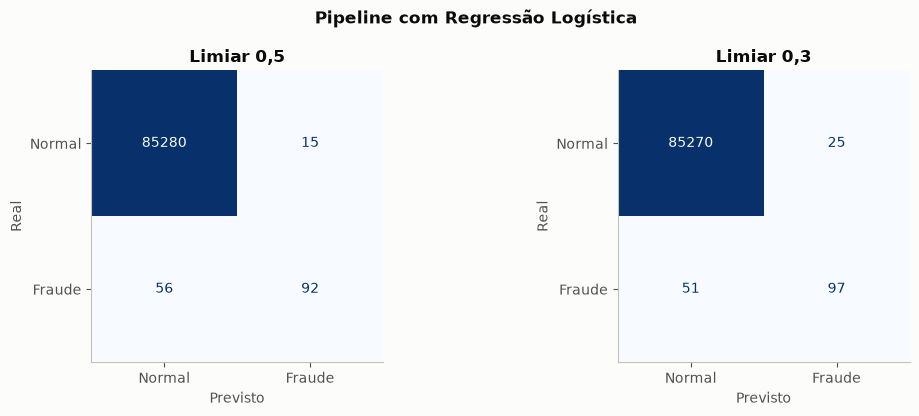

,Recall,Precisão,F1,Fraudes detectadas,Fraudes perdidas,Alarmes falsos
Limiar,,,,,,
0.5,0.622,0.860,0.722,92,56,15
0.3,0.655,0.795,0.719,97,51,25


In [22]:
def tabela_limiares(y_real, proba, limiares=(0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)):
    colunas = ['Recall', 'Precisão', 'F1', 'Fraudes detectadas', 'Fraudes perdidas', 'Alarmes falsos']
    linhas = []
    for limiar in limiares:
        resultado = metricas_fraude(y_real, proba, limiar)
        linhas.append({'Limiar': limiar, **{coluna: resultado[coluna] for coluna in colunas}})
    return pd.DataFrame(linhas).set_index('Limiar')


def grafico_limiares(y_real, proba, titulo, limiar_escolhido=None):
    limiares = np.round(np.linspace(0.01, 0.99, 99), 2)
    curvas = tabela_limiares(y_real, proba, limiares)
    fig, ax = plt.subplots(figsize=(10, 4))
    for metrica, cor in [('Recall', AZUL), ('Precisão', LARANJA), ('F1', AQUA)]:
        ax.plot(curvas.index, curvas[metrica], color=cor, label=metrica)
        ax.text(1.0, curvas[metrica].iloc[-1], f' {metrica}', color=TINTA_SECUNDARIA, va='center')
    for limiar, estilo in [(0.5, ':'), (0.3, '--')]:
        ax.axvline(limiar, color=TINTA_SUAVE, linestyle=estilo, linewidth=1)
        ax.text(limiar, 0.03, f' {br(limiar, 1)}', color=TINTA_SUAVE)
    if limiar_escolhido is not None:
        ax.axvline(limiar_escolhido, color=TINTA, linestyle='-', linewidth=1)
        ax.text(limiar_escolhido, 0.10, f' escolhido: {br(limiar_escolhido, 2)}', color=TINTA)
    ax.set_xlim(0, 1.1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel('Limiar de decisão')
    ax.set_ylabel('Métrica da classe fraude')
    ax.set_title(titulo, loc='left', pad=24)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncols=3)
    plt.tight_layout()
    plt.show()


fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, limiar in zip(eixos, [0.5, 0.3]):
    ConfusionMatrixDisplay.from_predictions(
        y_teste, (proba_pipeline_lr >= limiar).astype(int), display_labels=['Normal', 'Fraude'],
        cmap='Blues', colorbar=False, values_format='d', ax=ax
    )
    ax.set_title(f'Limiar {br(limiar, 1)}')
    ax.set_xlabel('Previsto')
    ax.set_ylabel('Real')
    ax.grid(False)
fig.suptitle('Pipeline com Regressão Logística', fontweight='bold', color=TINTA)
plt.tight_layout()
plt.show()

tabela_limiares(y_teste, proba_pipeline_lr, limiares=(0.5, 0.3)).round(3)

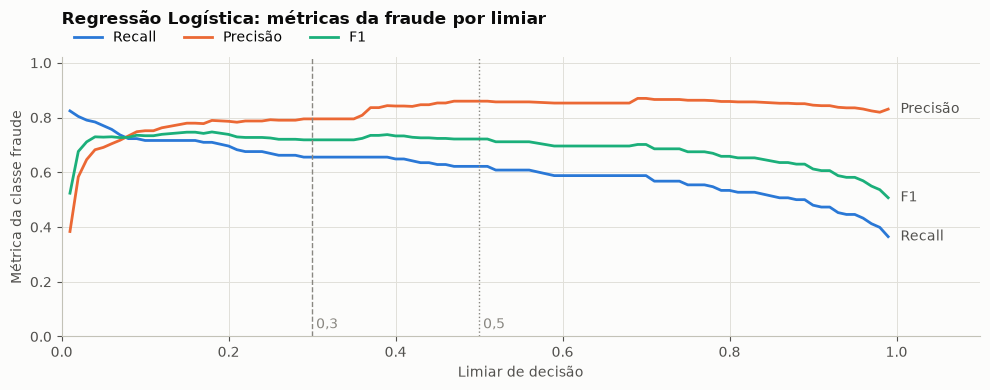

,Recall,Precisão,F1,Fraudes detectadas,Fraudes perdidas,Alarmes falsos
Limiar,,,,,,
0.05,0.770,0.691,0.728,114,34,51
0.10,0.716,0.752,0.734,106,42,35
0.20,0.696,0.786,0.738,103,45,28
0.30,0.655,0.795,0.719,97,51,25
0.40,0.649,0.842,0.733,96,52,18
0.50,0.622,0.860,0.722,92,56,15
0.60,0.588,0.853,0.696,87,61,15
0.70,0.588,0.870,0.702,87,61,13
0.80,0.534,0.859,0.658,79,69,13


In [23]:
registrar('Regressão Logística', 'Pipeline, limiar 0,3', y_teste, proba_pipeline_lr, 0.3)
grafico_limiares(y_teste, proba_pipeline_lr, 'Regressão Logística: métricas da fraude por limiar')
tabela_limiares(y_teste, proba_pipeline_lr).round(3)

Na Regressão Logística, baixar o limiar de 0,5 para 0,3 pega **5 fraudes a mais** (97 contra 92, recall de 0,622 para 0,655) ao custo de **10 alarmes falsos a mais** (25 contra 15, precisão de 0,860 para 0,795). O F1 fica praticamente igual (0,722 e 0,719).

A tabela mostra o padrão geral: limiar menor aumenta o recall e reduz a precisão. Mesmo com limiar 0,05 a Regressão Logística não passa de 0,77 de recall, porque o problema dela não é só o corte: ela ordena pior as transações (average precision 0,710). Ajustar o limiar escolhe um ponto da curva de precisão e recall, mas não melhora a curva.

### 5.3 GridSearchCV com `scoring='recall'`

Busca em grade sobre o pipeline da Regressão Logística, com validação cruzada estratificada de 5 folds (`StratifiedKFold`, cada fold com a mesma proporção de fraudes) feita **somente no treino**. A grade é enxuta (8 combinações, 40 ajustes) e roda em paralelo com `n_jobs=-1`:

- `C`: inverso da força da regularização (0,01 a 10).
- `class_weight`: sem peso ou `'balanced'`.

In [24]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

grade_lr = {
    'modelo__C': [0.01, 0.1, 1, 10],
    'modelo__class_weight': [None, 'balanced'],
}
busca_lr = GridSearchCV(pipeline_lr, grade_lr, scoring='recall', cv=validacao, n_jobs=-1)

inicio = time.time()
busca_lr.fit(X_treino, y_treino)
print(f'GridSearchCV concluído em {time.time() - inicio:.1f} s')
print(f'Melhores parâmetros: {busca_lr.best_params_}')
print(f'Recall médio na validação cruzada: {busca_lr.best_score_:.3f}')

resultados_grade = pd.DataFrame({
    'C': busca_lr.cv_results_['param_modelo__C'],
    'class_weight': [str(valor) for valor in busca_lr.cv_results_['param_modelo__class_weight']],
    'Recall médio (CV)': busca_lr.cv_results_['mean_test_score'],
    'Desvio (CV)': busca_lr.cv_results_['std_test_score'],
    'Posição': busca_lr.cv_results_['rank_test_score'],
})
resultados_grade.sort_values('Posição').reset_index(drop=True).round(3)

GridSearchCV concluído em 14.7 s
Melhores parâmetros: {'modelo__C': 10, 'modelo__class_weight': 'balanced'}
Recall médio na validação cruzada: 0.927


,C,class_weight,Recall médio (CV),Desvio (CV),Posição
0,10.00,balanced,0.927,0.009,1
1,0.10,balanced,0.921,0.015,2
2,1.00,balanced,0.921,0.015,2
3,0.01,balanced,0.919,0.015,4
4,1.00,None,0.645,0.026,5
5,10.00,None,0.645,0.026,5
6,0.10,None,0.637,0.017,7
7,0.01,None,0.605,0.026,8


Regressão Logística ajustada pelo GridSearchCV (limiar 0,50)

              precision    recall  f1-score   support

      Normal      1.000     0.978     0.989     85295
      Fraude      0.065     0.872     0.121       148

    accuracy                          0.978     85443
   macro avg      0.532     0.925     0.555     85443
weighted avg      0.998     0.978     0.987     85443



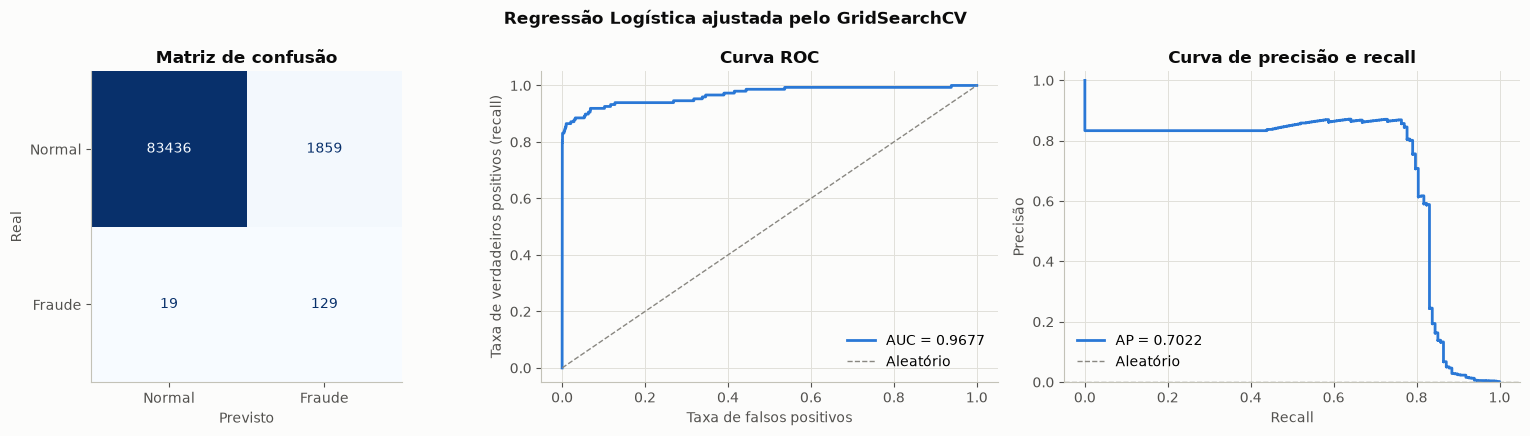

In [25]:
proba_busca_lr = busca_lr.predict_proba(X_teste)[:, 1]
melhor_c = busca_lr.best_params_['modelo__C']
melhor_peso = busca_lr.best_params_['modelo__class_weight']
registrar('Regressão Logística', f'GridSearchCV (recall): C={melhor_c}, class_weight={melhor_peso}', y_teste, proba_busca_lr)
avaliar('Regressão Logística ajustada pelo GridSearchCV', y_teste, proba_busca_lr, cor=AZUL)

Como o critério era **apenas recall**, a busca colocou `class_weight='balanced'` nas quatro primeiras posições: o recall na validação cruzada sobe de cerca de 0,64 para 0,93. No teste o recall vai a 0,872 (129 de 148 fraudes), mas a precisão despenca para 0,065: são **1.859 alarmes falsos** para 129 fraudes detectadas, cerca de 14 alertas errados para cada fraude real.

Essa é a armadilha de otimizar só o recall: o jeito mais fácil de aumentar o recall é marcar mais transações como fraude, e marcar todas dá recall 1. A busca fez exatamente o que foi pedido. A lição é que **o recall precisa vir acompanhado de uma restrição de precisão** (ou de uma métrica como F1 ou average precision), e é isso que as próximas seções fazem. A average precision do modelo da busca (0,702) é praticamente a mesma do baseline (0,710): o peso de classe empurrou as probabilidades para cima, mas não melhorou a capacidade de separar fraude de transação normal.

### 5.4 Evolução: undersampling contra oversampling (SMOTE)

Outra forma de lidar com o desbalanceamento é mexer nos dados de treino:

- **`RandomUnderSampler`:** descarta transações normais até ficarem tantas quanto as fraudes (cerca de 275 de cada por fold).
- **`SMOTE`:** cria fraudes sintéticas interpolando cada fraude com suas vizinhas mais próximas, até igualar o número de normais.

**O cuidado com vazamento.** Se a reamostragem fosse feita antes da validação cruzada, fraudes sintéticas criadas a partir de fraudes da validação entrariam no treino, e o recall ficaria inflado. O `Pipeline` do `imblearn` resolve isso: o amostrador só atua no `fit`, ou seja, apenas na parte de treino de cada fold. Na validação e no teste os dados continuam com a proporção real.

A comparação usa Regressão Logística e XGBoost (este **sem** `scale_pos_weight`, para isolar o efeito da reamostragem), com validação cruzada de 5 folds no treino e depois avaliação no teste.

In [26]:
amostradores = {
    'Sem reamostragem': None,
    'Undersampling (RandomUnderSampler)': RandomUnderSampler(random_state=SEMENTE),
    'Oversampling (SMOTE)': SMOTE(random_state=SEMENTE),
}
classificadores = {
    'Regressão Logística': lambda: LogisticRegression(max_iter=1000, random_state=SEMENTE),
    'XGBoost': lambda: criar_xgboost(),
}
metricas_cv = ['recall', 'precision', 'f1', 'average_precision']

linhas_reamostragem = []
inicio = time.time()
for nome_modelo, criar_modelo in classificadores.items():
    for nome_amostrador, amostrador in amostradores.items():
        etapas = [('padronizacao', StandardScaler())]
        if amostrador is not None:
            etapas.append(('reamostragem', amostrador))
        etapas.append(('modelo', criar_modelo()))
        pipeline = ImbPipeline(etapas)

        paralelo = -1 if nome_modelo == 'Regressão Logística' else 1
        cv = cross_validate(pipeline, X_treino, y_treino, cv=validacao, scoring=metricas_cv, n_jobs=paralelo)
        pipeline.fit(X_treino, y_treino)
        proba = pipeline.predict_proba(X_teste)[:, 1]
        teste = metricas_fraude(y_teste, proba)
        if amostrador is not None:
            registrar(nome_modelo, nome_amostrador, y_teste, proba)
        elif nome_modelo == 'XGBoost':
            registrar(nome_modelo, 'Sem reamostragem e sem scale_pos_weight', y_teste, proba)

        linhas_reamostragem.append({
            'Modelo': nome_modelo,
            'Reamostragem': nome_amostrador,
            'Recall CV': cv['test_recall'].mean(),
            'Recall CV (desvio)': cv['test_recall'].std(),
            'Precisão CV': cv['test_precision'].mean(),
            'F1 CV': cv['test_f1'].mean(),
            'AP CV': cv['test_average_precision'].mean(),
            'Recall teste': teste['Recall'],
            'Precisão teste': teste['Precisão'],
            'F1 teste': teste['F1'],
            'Alarmes falsos teste': teste['Alarmes falsos'],
        })
print(f'Comparação concluída em {time.time() - inicio:.1f} s')

tabela_reamostragem = pd.DataFrame(linhas_reamostragem).set_index(['Modelo', 'Reamostragem'])
tabela_reamostragem.round(3)

Comparação concluída em 59.0 s


Recall CV  Recall CV (desvio)  Precisão CV  F1 CV  AP CV  Recall teste  Precisão teste  F1 teste  Alarmes falsos teste
Modelo              Reamostragem                                                                                                                                              
Regressão Logística Sem reamostragem                        0.645               0.026        0.874  0.742  0.781         0.622           0.860     0.722                    15
                    Undersampling (RandomUnderSampler)      0.921               0.018        0.051  0.096  0.574         0.878           0.058     0.110                  2096
                    Oversampling (SMOTE)                    0.921               0.007        0.065  0.121  0.778         0.872           0.062     0.116                  1950
XGBoost             Sem reamostragem                        0.802               0.027        0.945  0.868  0.864         0.784           0.959     0.862                     5
                    Undersampling (RandomUnderSampler)      0.930               0.025        0.049  0.094  0.746         0.892           0.050     0.094                  2515
                    Oversampling (SMOTE)                    0.846               0.015        0.739  0.788  0.858         0.811           0.745     0.777                    41

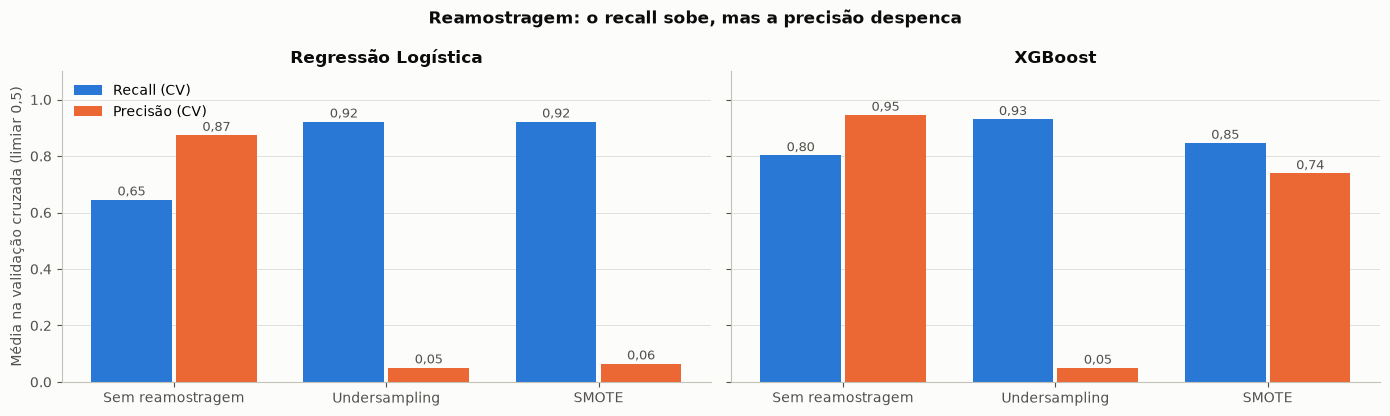

In [27]:
rotulos_curtos = {
    'Sem reamostragem': 'Sem reamostragem',
    'Undersampling (RandomUnderSampler)': 'Undersampling',
    'Oversampling (SMOTE)': 'SMOTE',
}
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, nome_modelo in zip(eixos, classificadores):
    parte = tabela_reamostragem.loc[nome_modelo]
    posicoes = np.arange(len(parte))
    largura = 0.38
    barras_recall = ax.bar(posicoes - largura / 2 - 0.01, parte['Recall CV'], largura, color=AZUL, label='Recall (CV)')
    barras_precisao = ax.bar(posicoes + largura / 2 + 0.01, parte['Precisão CV'], largura, color=LARANJA, label='Precisão (CV)')
    for barra in list(barras_recall) + list(barras_precisao):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.015, br(barra.get_height(), 2),
                ha='center', color=TINTA_SECUNDARIA, fontsize=9)
    ax.set_xticks(posicoes, [rotulos_curtos[r] for r in parte.index])
    ax.set_title(nome_modelo)
    ax.set_ylim(0, 1.1)
    ax.grid(axis='x', visible=False)
eixos[0].set_ylabel('Média na validação cruzada (limiar 0,5)')
eixos[0].legend(loc='upper left')
fig.suptitle('Reamostragem: o recall sobe, mas a precisão despenca', fontweight='bold', color=TINTA)
plt.tight_layout()
plt.show()

- **As duas técnicas aumentam o recall**, como esperado. Na Regressão Logística ele vai de 0,645 para 0,921 na validação cruzada, tanto com undersampling quanto com SMOTE. No XGBoost o undersampling chega a 0,930.
- **O preço é a precisão.** Com undersampling o modelo treina com apenas cerca de 275 transações normais por fold e passa a ver fraude em todo lugar: no teste são mais de 2 mil alarmes falsos (2.096 na Regressão Logística e 2.515 no XGBoost), com precisão de 5% a 6%. O SMOTE mantém todas as transações normais e por isso é bem mais equilibrado no XGBoost (recall 0,846 e precisão 0,739 na validação), mas na Regressão Logística ainda gera 1.950 alarmes falsos no teste.
- **Pelo recall, o undersampling vence** nos dois modelos. **Pelo equilíbrio, o SMOTE é a melhor das duas técnicas.** Mas nenhuma delas melhora a average precision: no XGBoost ela é 0,864 sem reamostragem, 0,858 com SMOTE e 0,746 com undersampling na validação cruzada.
- Ou seja, neste problema a reamostragem funciona basicamente como um jeito de mover o limiar. Ela não ensina o modelo a ordenar melhor as transações por risco, e o undersampling ainda joga fora informação útil.

Validação cruzada e teste contam a mesma história, sinal de que o `imblearn.pipeline` evitou o vazamento: não aparece um desempenho alto na validação que desapareça no teste. Os resultados de teste de cada variação entram na tabela final (seção 7).

### 5.5 Evolução: Random Forest no Pipeline com ajuste de limiar

Na seção 5.2 o limiar foi comparado olhando direto para o teste. Isso serve para ilustrar o efeito, mas **escolher o limiar no teste é uma forma de vazamento**: o teste deixa de ser uma estimativa honesta do desempenho em dados novos.

Aqui o processo é feito do jeito certo:

1. O Random Forest entra num `Pipeline` (padronização + modelo). A padronização não muda as árvores, mas o pipeline mantém a mesma interface dos outros modelos e evita passos manuais.
2. Com `cross_val_predict` (5 folds estratificados), cada transação do **treino** recebe uma probabilidade prevista por um modelo que não a viu (previsão fora da amostra).
3. O limiar é escolhido nessas previsões, com uma regra de negócio explícita: **o maior recall possível mantendo a precisão em pelo menos 80%**, ou seja, no máximo 1 alarme falso para cada 4 fraudes detectadas. Entre limiares com o mesmo recall, fica o de maior precisão.
4. O pipeline é treinado no treino inteiro e o limiar escolhido é aplicado **uma única vez** no teste.

`PRECISAO_MINIMA` é um parâmetro de negócio: se a equipe de análise tiver mais capacidade, ele pode descer e o recall sobe.

In [28]:
PRECISAO_MINIMA = 0.80
LIMIARES_CANDIDATOS = np.round(np.arange(0.05, 0.96, 0.05), 2)


def escolher_limiar(y_real, proba, precisao_minima=PRECISAO_MINIMA, limiares=LIMIARES_CANDIDATOS):
    tabela = tabela_limiares(y_real, proba, limiares)
    candidatos = tabela[tabela['Precisão'] >= precisao_minima]
    if candidatos.empty:
        return float(tabela['F1'].idxmax()), tabela
    return float(candidatos.sort_values(['Recall', 'Precisão'], ascending=False).index[0]), tabela


pipeline_rf = Pipeline([
    ('padronizacao', StandardScaler()),
    ('modelo', criar_random_forest()),
])

inicio = time.time()
proba_oof_rf = cross_val_predict(pipeline_rf, X_treino, y_treino, cv=validacao, method='predict_proba')[:, 1]
limiar_rf, tabela_oof_rf = escolher_limiar(y_treino, proba_oof_rf)
pipeline_rf.fit(X_treino, y_treino)
proba_pipeline_rf = pipeline_rf.predict_proba(X_teste)[:, 1]
print(f'Validação cruzada e treino final em {time.time() - inicio:.1f} s')
print(f'Limiar escolhido nas previsões fora da amostra do treino: {limiar_rf:.2f}')

tabela_oof_rf.round(3)

Validação cruzada e treino final em 71.2 s
Limiar escolhido nas previsões fora da amostra do treino: 0.25


,Recall,Precisão,F1,Fraudes detectadas,Fraudes perdidas,Alarmes falsos
Limiar,,,,,,
0.05,0.881,0.450,0.595,303,41,371
0.10,0.863,0.644,0.738,297,47,164
0.15,0.855,0.735,0.790,294,50,106
0.20,0.849,0.787,0.817,292,52,79
0.25,0.834,0.813,0.824,287,57,66
0.30,0.831,0.856,0.844,286,58,48
0.35,0.828,0.877,0.852,285,59,40
0.40,0.826,0.890,0.857,284,60,35
0.45,0.811,0.903,0.855,279,65,30


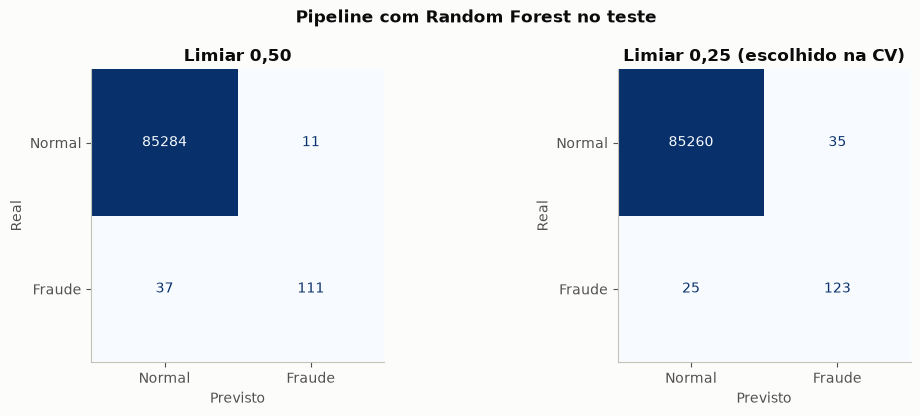

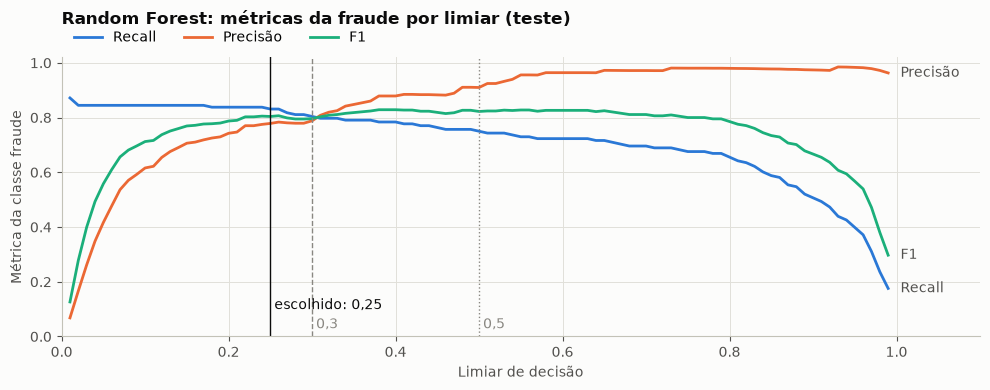

,Recall,Precisão,F1,Fraudes detectadas,Fraudes perdidas,Alarmes falsos
Limiar,,,,,,
0.50,0.750,0.910,0.822,111,37,11
0.30,0.804,0.788,0.796,119,29,32
0.25,0.831,0.778,0.804,123,25,35


In [29]:
registrar('Random Forest', f'Pipeline, limiar escolhido na CV ({br(limiar_rf, 2)})', y_teste, proba_pipeline_rf, limiar_rf)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, limiar in zip(eixos, [0.5, limiar_rf]):
    ConfusionMatrixDisplay.from_predictions(
        y_teste, (proba_pipeline_rf >= limiar).astype(int), display_labels=['Normal', 'Fraude'],
        cmap='Blues', colorbar=False, values_format='d', ax=ax
    )
    ax.set_title(f'Limiar {br(limiar, 2)}' + (' (escolhido na CV)' if limiar == limiar_rf else ''))
    ax.set_xlabel('Previsto')
    ax.set_ylabel('Real')
    ax.grid(False)
fig.suptitle('Pipeline com Random Forest no teste', fontweight='bold', color=TINTA)
plt.tight_layout()
plt.show()

grafico_limiares(y_teste, proba_pipeline_rf, 'Random Forest: métricas da fraude por limiar (teste)', limiar_escolhido=limiar_rf)
tabela_limiares(y_teste, proba_pipeline_rf, limiares=(0.5, 0.3, limiar_rf)).round(3)

- Nas previsões fora da amostra do treino, 0,25 é o menor limiar (ou seja, o de maior recall) que ainda mantém a precisão em pelo menos 80%: recall 0,834 e precisão 0,813. Com 0,20 a precisão já cai para 0,787.
- No teste, o limiar 0,25 aumenta o recall do Random Forest de 0,750 para 0,831: são **12 fraudes a mais detectadas** (123 contra 111), com 24 alarmes falsos a mais (35 contra 11). A precisão no teste (0,778) ficou um pouco abaixo dos 80% da validação, variação esperada com apenas 148 fraudes no teste.
- Como o limiar foi escolhido sem olhar o teste, esse resultado é uma estimativa honesta de como o modelo se comportaria em dados novos.

### 5.6 Evolução: variáveis de comportamento ao longo do tempo

`Time` sozinho é só um relógio que cresce ao longo de dois dias. Mas, como a base está em ordem cronológica, dá para derivar dele variáveis que descrevem **o contexto em que a transação aconteceu**:

| Grupo | Variáveis | Ideia |
|---|---|---|
| Hora do dia | `Hora_sin`, `Hora_cos` | Hora relativa (`Time` em horas, módulo 24) codificada como ciclo, para que 23h fique perto de 0h. A exploração mostrou taxa de fraude bem maior de madrugada. |
| Ritmo das transações | `Segundos_desde_anterior`, `Transacoes_ultima_hora` | Intervalo desde a transação anterior e volume de transações na hora anterior. Medem o movimento do sistema naquele momento. |
| Repetição de valor | `Mesmo_valor_ultima_hora`, `Segundos_desde_mesmo_valor` | Quantas transações com exatamente o mesmo valor ocorreram na hora anterior e há quanto tempo apareceu a última. Fraudes de teste de cartão costumam repetir valores. |

Todas usam **apenas transações anteriores** e nenhuma usa a variável resposta, então estariam disponíveis em produção no momento da transação. Por isso podem ser calculadas na base ordenada antes da divisão, sem vazamento.

O teste é feito com o XGBoost (melhor modelo até aqui), comparando o recall na validação cruzada de 5 folds e no teste. Os folds são os mesmos para todos os conjuntos, o que permite comparar fold a fold.

In [30]:
print(f"Base em ordem cronológica: {df['Time'].is_monotonic_increasing}")


def contar_ultima_hora(tempos):
    valores = np.asarray(tempos)
    return np.arange(len(valores)) - np.searchsorted(valores, valores - 3600, side='left')


df['Hora'] = (df['Time'] // 3600) % 24
df['Hora_sin'] = np.sin(2 * np.pi * df['Hora'] / 24)
df['Hora_cos'] = np.cos(2 * np.pi * df['Hora'] / 24)
df['Segundos_desde_anterior'] = df['Time'].diff().fillna(0)
df['Transacoes_ultima_hora'] = contar_ultima_hora(df['Time'])
df['Mesmo_valor_ultima_hora'] = df.groupby('Amount', sort=False)['Time'].transform(contar_ultima_hora)
df['Segundos_desde_mesmo_valor'] = df.groupby('Amount', sort=False)['Time'].diff().fillna(df['Time'].max())

GRUPOS_TEMPO = {
    'hora do dia': ['Hora_sin', 'Hora_cos'],
    'ritmo das transações': ['Segundos_desde_anterior', 'Transacoes_ultima_hora'],
    'repetição de valor': ['Mesmo_valor_ultima_hora', 'Segundos_desde_mesmo_valor'],
}
VARIAVEIS_TEMPO = [variavel for grupo in GRUPOS_TEMPO.values() for variavel in grupo]

resumo_tempo = df.groupby('Class')[['Hora'] + VARIAVEIS_TEMPO[2:]].agg(['median', 'mean']).rename(index=nomes_classe).T
resumo_tempo.round(2)

Base em ordem cronológica: True


Class                                Normal    Fraude
Hora                       median     15.00     12.00
                           mean       14.05     11.65
Segundos_desde_anterior    median      0.00      0.00
                           mean        0.61      1.09
Transacoes_ultima_hora     median   7942.00   7773.00
                           mean     7247.37   6083.75
Mesmo_valor_ultima_hora    median      2.00      2.00
                           mean       39.68     55.61
Segundos_desde_mesmo_valor median    770.00    426.00
                           mean    25354.68  35020.42

As classes diferem nessas variáveis. Em média, as fraudes acontecem mais cedo no ciclo de 24 horas (11,6h contra 14,1h, efeito da madrugada), com mais tempo desde a transação anterior (1,09 s contra 0,61 s, isto é, em momentos de menor movimento) e com menos transações na hora anterior (6.084 contra 7.247). Na repetição de valor as medianas empatam, mas as fraudes repetem o mesmo valor mais vezes na hora anterior (média de 55,6 contra 39,7) e em intervalos mais curtos (mediana de 426 s contra 770 s).

A pergunta que importa é outra: esse sinal acrescenta algo ao que `V1` a `V28` já capturam?

In [31]:
conjuntos = {'Originais': VARIAVEIS}
for nome_grupo, colunas in GRUPOS_TEMPO.items():
    conjuntos[f'Originais + {nome_grupo}'] = VARIAVEIS + colunas
conjuntos['Originais + todas as de tempo'] = VARIAVEIS + VARIAVEIS_TEMPO

linhas_tempo = []
recall_por_fold = {}
probabilidades_tempo = {}
inicio = time.time()
for nome, colunas in conjuntos.items():
    modelo = criar_xgboost(scale_pos_weight=peso_fraude)
    cv = cross_validate(modelo, df.loc[X_treino.index, colunas], y_treino, cv=validacao, scoring=metricas_cv)
    modelo.fit(df.loc[X_treino.index, colunas], y_treino)
    probabilidades_tempo[nome] = modelo.predict_proba(df.loc[X_teste.index, colunas])[:, 1]
    teste = metricas_fraude(y_teste, probabilidades_tempo[nome])
    recall_por_fold[nome] = cv['test_recall']
    linhas_tempo.append({
        'Conjunto de variáveis': nome,
        'Nº de variáveis': len(colunas),
        'Recall CV': cv['test_recall'].mean(),
        'Recall CV (desvio)': cv['test_recall'].std(),
        'Precisão CV': cv['test_precision'].mean(),
        'F1 CV': cv['test_f1'].mean(),
        'AP CV': cv['test_average_precision'].mean(),
        'Recall teste': teste['Recall'],
        'Precisão teste': teste['Precisão'],
        'F1 teste': teste['F1'],
        'AP teste': teste['Average precision'],
    })
print(f'Comparação concluída em {time.time() - inicio:.1f} s')

tabela_tempo = pd.DataFrame(linhas_tempo).set_index('Conjunto de variáveis')
tabela_tempo.round(3)

Comparação concluída em 88.5 s


,Nº de variáveis,Recall CV,Recall CV (desvio),Precisão CV,F1 CV,AP CV,Recall teste,Precisão teste,F1 teste,AP teste
Conjunto de variáveis,,,,,,,,,,
Originais,30,0.831,0.024,0.892,0.860,0.863,0.791,0.886,0.836,0.838
Originais + hora do dia,32,0.828,0.022,0.887,0.856,0.863,0.804,0.902,0.850,0.840
Originais + ritmo das transações,32,0.828,0.022,0.884,0.855,0.863,0.797,0.901,0.846,0.842
Originais + repetição de valor,32,0.834,0.026,0.890,0.860,0.868,0.797,0.901,0.846,0.844
Originais + todas as de tempo,36,0.840,0.019,0.880,0.859,0.863,0.791,0.893,0.839,0.842


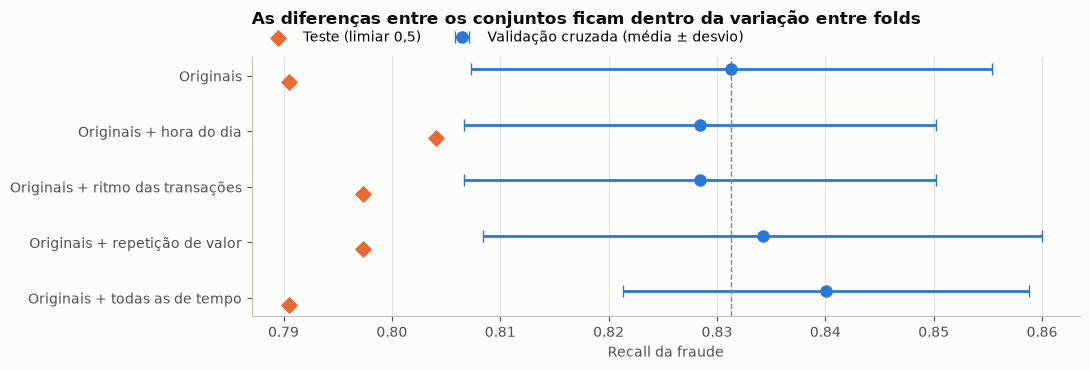

Recall de cada fold da validação cruzada:


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Originais,0.855,0.797,0.855,0.841,0.809
Originais + hora do dia,0.855,0.797,0.841,0.841,0.809
Originais + ritmo das transações,0.855,0.797,0.841,0.841,0.809
Originais + repetição de valor,0.855,0.797,0.855,0.855,0.809
Originais + todas as de tempo,0.855,0.812,0.855,0.855,0.824


,Ganho médio de recall (p.p.),Folds com ganho,Folds com perda,Ganho de recall no teste (p.p.)
Originais + hora do dia,-0.29,0,1,1.35
Originais + ritmo das transações,-0.29,0,1,0.68
Originais + repetição de valor,0.29,1,0,0.68
Originais + todas as de tempo,0.87,3,0,0.00


In [32]:
folds = pd.DataFrame(recall_por_fold, index=[f'Fold {i}' for i in range(1, 6)])
ganho_por_fold = folds.drop(columns='Originais').sub(folds['Originais'], axis=0)
resumo_ganho = pd.DataFrame({
    'Ganho médio de recall (p.p.)': ganho_por_fold.mean() * 100,
    'Folds com ganho': (ganho_por_fold > 0).sum(),
    'Folds com perda': (ganho_por_fold < 0).sum(),
    'Ganho de recall no teste (p.p.)': (tabela_tempo['Recall teste'] - tabela_tempo.loc['Originais', 'Recall teste']).drop('Originais') * 100,
})

fig, ax = plt.subplots(figsize=(11, 3.8))
posicoes = np.arange(len(tabela_tempo))
ax.errorbar(tabela_tempo['Recall CV'], posicoes - 0.12, xerr=tabela_tempo['Recall CV (desvio)'], fmt='o',
            color=AZUL, ecolor=AZUL, elinewidth=2, capsize=4, markersize=8, label='Validação cruzada (média ± desvio)')
ax.scatter(tabela_tempo['Recall teste'], posicoes + 0.12, color=LARANJA, marker='D', s=60, zorder=3,
           label='Teste (limiar 0,5)')
ax.axvline(tabela_tempo.loc['Originais', 'Recall CV'], color=TINTA_SUAVE, linestyle='--', linewidth=1)
ax.set_yticks(posicoes, tabela_tempo.index)
ax.invert_yaxis()
ax.set_xlabel('Recall da fraude')
ax.set_title('As diferenças entre os conjuntos ficam dentro da variação entre folds', loc='left', pad=24)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncols=2)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Recall de cada fold da validação cruzada:')
display(folds.T.round(3))
resumo_ganho.round(2)

**Resultado: as variáveis de tempo quase não mudam o recall.**

- Na validação cruzada, o maior ganho veio do conjunto com todas as variáveis de tempo: recall médio de 0,840 contra 0,831 dos originais (+0,9 ponto percentual), com ganho em 3 dos 5 folds e nenhuma perda. É um ganho pequeno, menor que o desvio entre folds (cerca de 0,02).
- No teste, com limiar 0,5, esse conjunto tem o mesmo recall dos originais (0,791, 117 fraudes), com precisão um pouco maior (0,893 contra 0,886) e average precision de 0,842 contra 0,838. A hora do dia sozinha pegou 2 fraudes a mais no teste (recall 0,804), mas não repetiu isso na validação cruzada (−0,3 ponto percentual).
- Os sinais vistos na exploração (madrugada, ritmo do sistema) são reais, mas o modelo já os capturava de forma indireta pelas variáveis do PCA e pelo próprio `Time`.

O motivo mais provável é a falta de um identificador de cartão ou de cliente. As variáveis de comportamento que costumam fazer diferença em fraude são **por cartão**: quantas compras aquele cartão fez na última hora, se o valor foge do padrão dele, se mudou de cidade. Nesta base só dá para medir o comportamento do sistema inteiro, um sinal bem mais fraco.

Pelo critério adotado (maior recall médio na validação cruzada, sem olhar o teste), o conjunto com todas as variáveis de tempo segue para o modelo final, sabendo que o ganho é pequeno.

### 5.7 Modelo final: XGBoost com limiar escolhido na validação cruzada

O modelo final junta o que funcionou melhor:

- **XGBoost com `scale_pos_weight`**, que teve a maior average precision em todas as comparações (é o modelo que melhor ordena as transações por risco).
- **O conjunto de variáveis com maior recall médio na validação cruzada** da seção 5.6 (a escolha é feita no treino, nunca no teste).
- **Limiar escolhido pela mesma regra da seção 5.5** (maior recall com precisão de pelo menos 80% nas previsões fora da amostra do treino).

O XGBoost não precisa de padronização (árvores só olham a ordem dos valores), então vai sem `Pipeline`.

In [33]:
melhor_conjunto = tabela_tempo['Recall CV'].idxmax()
VARIAVEIS_FINAIS = conjuntos[melhor_conjunto]
X_treino_final = df.loc[X_treino.index, VARIAVEIS_FINAIS]
X_teste_final = df.loc[X_teste.index, VARIAVEIS_FINAIS]
print(f'Conjunto escolhido: {melhor_conjunto} ({len(VARIAVEIS_FINAIS)} variáveis)')

modelo_final = criar_xgboost(scale_pos_weight=peso_fraude)
inicio = time.time()
proba_oof_final = cross_val_predict(modelo_final, X_treino_final, y_treino, cv=validacao, method='predict_proba')[:, 1]
limiar_final, tabela_oof_final = escolher_limiar(y_treino, proba_oof_final)
modelo_final.fit(X_treino_final, y_treino)
proba_final = modelo_final.predict_proba(X_teste_final)[:, 1]
print(f'Validação cruzada e treino final em {time.time() - inicio:.1f} s')
print(f'Limiar escolhido nas previsões fora da amostra do treino: {limiar_final:.2f}')
print(f'Average precision fora da amostra (treino): Random Forest {average_precision_score(y_treino, proba_oof_rf):.3f} | XGBoost final {average_precision_score(y_treino, proba_oof_final):.3f}')

tabela_oof_final.round(3)

Conjunto escolhido: Originais + todas as de tempo (36 variáveis)


Validação cruzada e treino final em 20.5 s
Limiar escolhido nas previsões fora da amostra do treino: 0.15
Average precision fora da amostra (treino): Random Forest 0.855 | XGBoost final 0.863


,Recall,Precisão,F1,Fraudes detectadas,Fraudes perdidas,Alarmes falsos
Limiar,,,,,,
0.05,0.855,0.724,0.784,294,50,112
0.10,0.849,0.781,0.813,292,52,82
0.15,0.846,0.820,0.833,291,53,64
0.20,0.843,0.833,0.838,290,54,58
0.25,0.840,0.850,0.845,289,55,51
0.30,0.840,0.863,0.851,289,55,46
0.35,0.840,0.865,0.853,289,55,45
0.40,0.840,0.870,0.855,289,55,43
0.45,0.840,0.876,0.858,289,55,41


XGBoost final (limiar 0,15)

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     85295
      Fraude      0.831     0.831     0.831       148

    accuracy                          0.999     85443
   macro avg      0.915     0.915     0.915     85443
weighted avg      0.999     0.999     0.999     85443



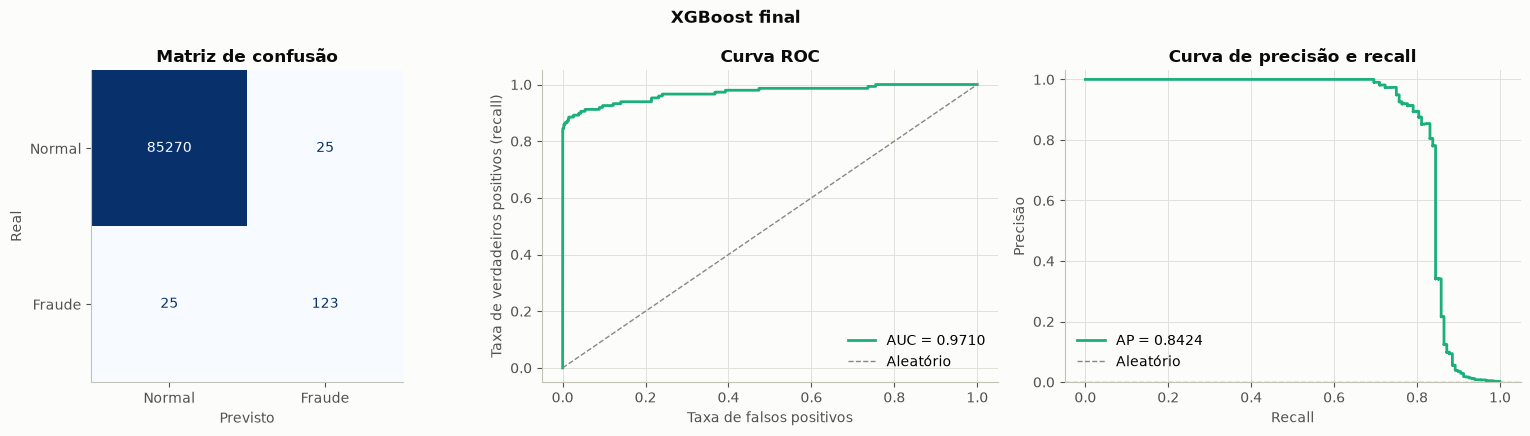

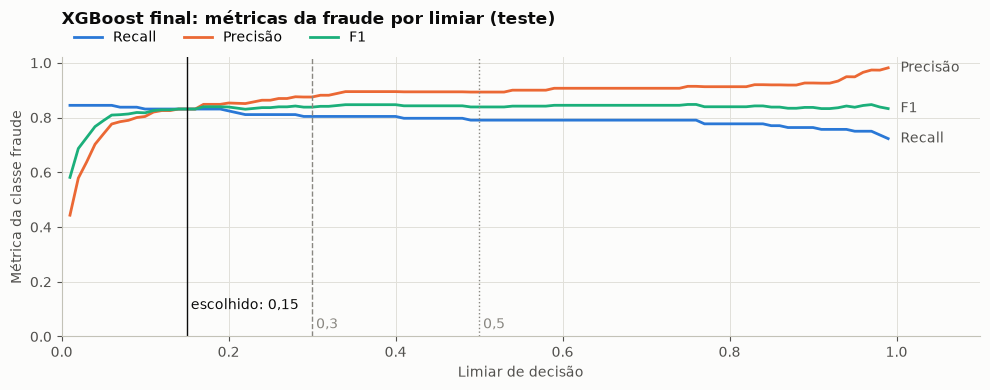

,Recall,Precisão,F1,Fraudes detectadas,Fraudes perdidas,Alarmes falsos
Limiar,,,,,,
0.50,0.791,0.893,0.839,117,31,14
0.30,0.804,0.875,0.838,119,29,17
0.15,0.831,0.831,0.831,123,25,25


In [34]:
if melhor_conjunto != 'Originais':
    registrar('XGBoost', f'{melhor_conjunto}, limiar 0,5', y_teste, proba_final)
registrar('XGBoost', f'Modelo final: {melhor_conjunto.lower()}, limiar escolhido na CV ({br(limiar_final, 2)})', y_teste, proba_final, limiar_final)
avaliar('XGBoost final', y_teste, proba_final, limiar=limiar_final, cor=AQUA)
grafico_limiares(y_teste, proba_final, 'XGBoost final: métricas da fraude por limiar (teste)', limiar_escolhido=limiar_final)
tabela_limiares(y_teste, proba_final, limiares=(0.5, 0.3, limiar_final)).round(3)

**Por que XGBoost:** nas previsões fora da amostra do treino, o XGBoost final tem average precision de 0,863 contra 0,855 do Random Forest. Ele ordena melhor as transações por risco e, por isso, chega ao mesmo recall com menos alarmes falsos.

**Limiar escolhido: 0,15.** É o menor limiar com precisão de pelo menos 80% nas previsões fora da amostra do treino (recall 0,846, precisão 0,820).

**No teste:**

- Recall de **0,831**: 123 das 148 fraudes detectadas, contra 117 com o limiar 0,5.
- Precisão de **0,831**: 25 alarmes falsos, contra 14 com o limiar 0,5.
- A troca é de 11 alarmes falsos a mais (em mais de 85 mil transações) por 6 fraudes a mais detectadas. Em fraude de cartão essa troca costuma compensar: uma fraude perdida é prejuízo direto, enquanto um alarme falso custa uma verificação.
- Comparado ao Random Forest com limiar ajustado (seção 5.5), o XGBoost final detecta as mesmas 123 fraudes com 10 alarmes falsos a menos (25 contra 35).

O recall do XGBoost varia menos com o limiar do que o do Random Forest porque o `scale_pos_weight` empurra as probabilidades para os extremos. Nas previsões fora da amostra, 50 das 344 fraudes do treino (14,5%) recebem probabilidade abaixo de 0,05: são casos que se parecem com transações normais, e nenhum limiar razoável os recupera sem disparar uma enxurrada de alarmes falsos.

## 6. Explicar o modelo

### 6.1 Importância das variáveis

O melhor modelo de árvore é o XGBoost final. A importância nativa do XGBoost (`feature_importances_`) mede o **ganho médio** que cada variável traz nas divisões das árvores: diz quais variáveis o modelo mais usa, mas não diz em que direção elas empurram a previsão.

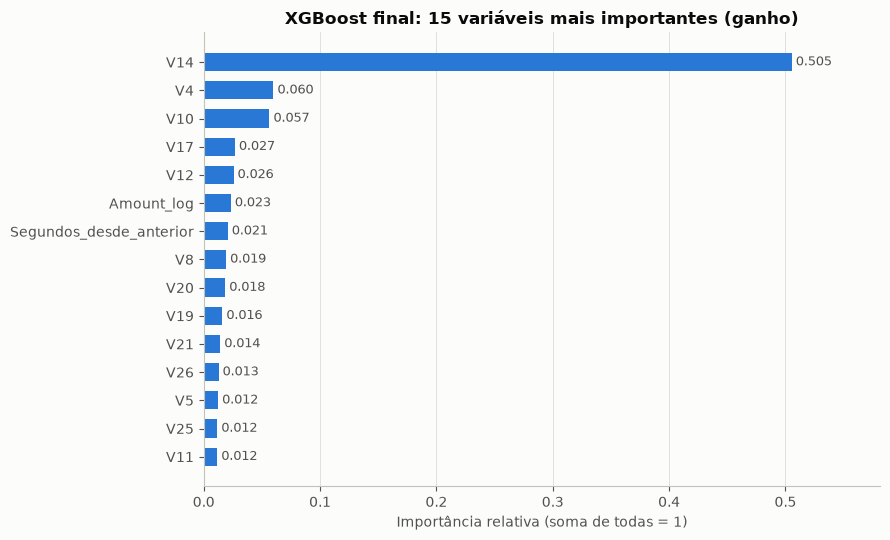

Posição das variáveis de tempo no ranking de importância:
Time                          30
Hora_sin                      36
Hora_cos                      34
Segundos_desde_anterior        7
Transacoes_ultima_hora        33
Mesmo_valor_ultima_hora       26
Segundos_desde_mesmo_valor    24


In [35]:
importancias = pd.Series(modelo_final.feature_importances_, index=VARIAVEIS_FINAIS).sort_values()
top_importancias = importancias.tail(15)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_importancias.index, top_importancias.values, color=AZUL, height=0.65)
for posicao, valor in enumerate(top_importancias.values):
    ax.text(valor, posicao, f' {valor:.3f}', va='center', color=TINTA_SECUNDARIA, fontsize=9)
ax.set_title('XGBoost final: 15 variáveis mais importantes (ganho)')
ax.set_xlabel('Importância relativa (soma de todas = 1)')
ax.set_xlim(0, top_importancias.max() * 1.15)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

posicao_tempo = importancias.rank(ascending=False).astype(int)
print('Posição das variáveis de tempo no ranking de importância:')
print(posicao_tempo.reindex([v for v in ['Time'] + VARIAVEIS_TEMPO if v in VARIAVEIS_FINAIS]).to_string())

### 6.2 SHAP

O SHAP distribui a previsão de cada transação entre as variáveis: para cada linha, mostra quanto cada variável aumentou ou reduziu o risco em relação a uma referência. O `TreeExplainer` calcula esses valores de forma exata para modelos de árvore.

**Referência (fundo):** 100 transações sorteadas do treino, praticamente todas normais, no modo `interventional`. Assim o valor base do SHAP é a previsão do modelo para uma transação típica e cada valor SHAP responde à pergunta "o que nesta transação a afasta de uma transação comum?". O modo padrão do `TreeExplainer` usa a cobertura das árvores como referência, e no XGBoost essa cobertura fica distorcida pelo `scale_pos_weight` de 578: o valor base deixaria de representar uma transação típica.

**Amostra explicada:** 700 transações normais sorteadas do teste mais **todas as 148 fraudes do teste**. Numa amostra aleatória pura quase não entrariam fraudes e o gráfico mostraria só o comportamento das normais. A amostra foi limitada a cerca de 850 transações para o cálculo levar poucos segundos.

Os valores estão na escala de **log-odds** do XGBoost: positivos empurram para fraude, negativos para normal.

Valores SHAP de 848 transações calculados em 7.2 s
Valor base (transação típica): -11.83 em log-odds, ou probabilidade de fraude de 0.000007


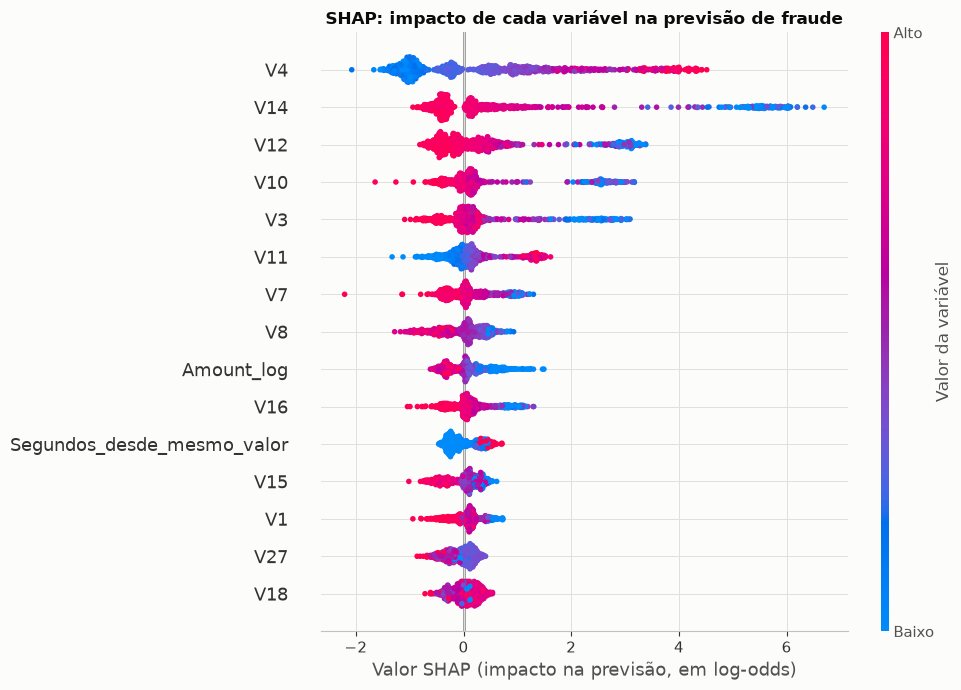

In [36]:
fundo_shap = X_treino_final.sample(100, random_state=SEMENTE)
amostra_shap = pd.concat([
    X_teste_final[y_teste == 0].sample(700, random_state=SEMENTE),
    X_teste_final[y_teste == 1],
])

explicador = shap.TreeExplainer(modelo_final, data=fundo_shap, feature_perturbation='interventional')
inicio = time.time()
valores_shap = explicador(amostra_shap)
if valores_shap.values.ndim == 3:
    valores_shap = valores_shap[:, :, 1]
valor_base = float(np.ravel(explicador.expected_value)[-1])
print(f'Valores SHAP de {len(amostra_shap)} transações calculados em {time.time() - inicio:.1f} s')
print(f'Valor base (transação típica): {valor_base:.2f} em log-odds, ou probabilidade de fraude de {1 / (1 + np.exp(-valor_base)):.6f}')

shap.summary_plot(valores_shap.values, amostra_shap, max_display=15, show=False, plot_size=(10, 7))
figura = plt.gcf()
figura.axes[0].set_xlabel('Valor SHAP (impacto na previsão, em log-odds)')
figura.axes[-1].set_ylabel('Valor da variável')
figura.axes[-1].set_yticklabels(['Baixo', 'Alto'])
figura.axes[0].set_title('SHAP: impacto de cada variável na previsão de fraude', color=TINTA, fontweight='bold')
plt.tight_layout()
plt.show()

In [37]:
impacto_medio = pd.Series(np.abs(valores_shap.values).mean(axis=0), index=VARIAVEIS_FINAIS)
pd.DataFrame({
    'Impacto médio |SHAP|': impacto_medio,
    'Posição no SHAP': impacto_medio.rank(ascending=False).astype(int),
    'Posição no ganho': importancias.rank(ascending=False).astype(int),
}).sort_values('Posição no SHAP').head(12).round(3)

,Impacto médio |SHAP|,Posição no SHAP,Posição no ganho
V4,1.317,1,2
V14,1.164,2,1
V12,0.711,3,5
V10,0.519,4,3
V3,0.480,5,29
V11,0.348,6,15
V7,0.321,7,22
V8,0.315,8,8
Amount_log,0.292,9,6
V16,0.262,10,31


**O que o SHAP mostra:**

- **V4, V14, V12, V10 e V3 concentram a maior parte do impacto.** O padrão de cada uma é nítido: valores **altos** de V4 e V11 empurram para fraude, e valores **baixos** (muito negativos) de V14, V12, V10 e V3 também. V14 dá os maiores empurrões individuais: em algumas fraudes ela sozinha soma mais de 6 em log-odds.
- **Ganho e SHAP não contam a mesma história.** No ganho do XGBoost, V14 sozinha responde por metade da importância (0,505), porque é usada nas primeiras divisões das árvores, que separam a maior parte das fraudes. O SHAP distribui o crédito de forma mais equilibrada e revela variáveis que o ganho subestima: V3 é a 5ª no SHAP e só a 29ª no ganho. O ganho mede o quanto o modelo usa a variável; o SHAP mede o quanto ela muda as previsões.
- **Valor baixo aumenta o risco:** os pontos azuis de `Amount_log` ficam à direita, ou seja, transações de valor baixo empurram levemente para fraude, coerente com o pico de fraudes em valores muito pequenos visto na exploração.
- **Das variáveis de tempo, só `Segundos_desde_mesmo_valor` aparece entre as 15 de maior impacto** (11ª posição): valores que não apareciam havia muito tempo deixam a transação um pouco mais suspeita. As demais têm impacto pequeno, o que confirma o resultado da seção 5.6.
- Como V1 a V28 são componentes de PCA anonimizados, o SHAP diz **quais componentes** pesam, mas não permite traduzir isso em regras de negócio (como "compra em outro país"). Com as variáveis originais, a mesma análise seria diretamente interpretável.

### 6.3 Explicação de uma transação marcada como fraude

A transação abaixo é uma fraude real do teste que o modelo marcou como fraude. Foi escolhida a de probabilidade mais próxima da mediana entre as fraudes detectadas, ou seja, um caso típico, nem o mais óbvio nem o mais difícil.

O gráfico de cascata (waterfall) parte do valor base `E[f(X)]` (a previsão do modelo para uma transação típica, em log-odds) e soma a contribuição de cada variável até chegar à previsão `f(x)` daquela transação.

Transação 45732 | classe real: fraude | probabilidade prevista: 0.9999 | limiar: 0.15
Valor da transação: 1,00 | hora relativa: 11h


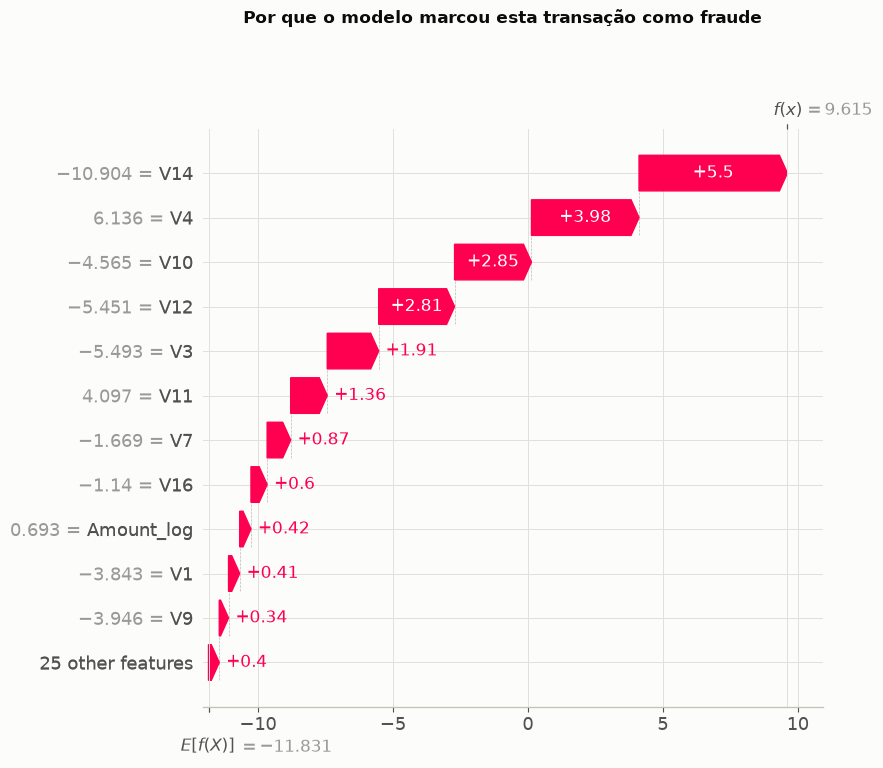

,Valor na transação,Contribuição SHAP (log-odds)
V14,-10.904,5.497
V4,6.136,3.985
V10,-4.565,2.848
V12,-5.451,2.812
V3,-5.493,1.905
V11,4.097,1.355
V7,-1.669,0.872
V16,-1.140,0.599


In [38]:
risco_teste = pd.Series(proba_final, index=X_teste_final.index)
fraudes_detectadas = risco_teste[(y_teste == 1) & (risco_teste >= limiar_final)]
indice_exemplo = (fraudes_detectadas - fraudes_detectadas.median()).abs().idxmin()

explicacao_exemplo = explicador(X_teste_final.loc[[indice_exemplo]])
if explicacao_exemplo.values.ndim == 3:
    explicacao_exemplo = explicacao_exemplo[:, :, 1]

print(f'Transação {indice_exemplo} | classe real: fraude | probabilidade prevista: {risco_teste[indice_exemplo]:.4f} | limiar: {limiar_final:.2f}')
print(f"Valor da transação: {br(df.loc[indice_exemplo, 'Amount'])} | hora relativa: {int(df.loc[indice_exemplo, 'Hora'])}h")

shap.plots.waterfall(explicacao_exemplo[0], max_display=12, show=False)
figura = plt.gcf()
figura.suptitle('Por que o modelo marcou esta transação como fraude', color=TINTA, fontweight='bold', y=1.04)
plt.show()

contribuicoes = pd.DataFrame({
    'Valor na transação': X_teste_final.loc[indice_exemplo],
    'Contribuição SHAP (log-odds)': explicacao_exemplo.values[0],
}).sort_values('Contribuição SHAP (log-odds)', key=np.abs, ascending=False)
contribuicoes.head(8).round(3)

A transação 45732 é uma fraude de **1,00**, valor baixo comum em testes de cartão. O modelo atribuiu a ela probabilidade de 0,9999.

- O ponto de partida é −11,83 em log-odds (0,0007% de risco para uma transação típica). A soma das contribuições leva a previsão a +9,62 (99,99%).
- **V14 = −10,9** dá o maior empurrão (+5,50). Para comparação, 75% das transações da base têm V14 acima de −0,43: esse valor está muito fora do padrão.
- **V4 = 6,14** (+3,98), **V10 = −4,57** (+2,85), **V12 = −5,45** (+2,81) e **V3 = −5,49** (+1,91) completam o quadro, todas na direção que o gráfico de resumo apontou como típica de fraude.
- O valor baixo (`Amount_log` = 0,69, que corresponde a 1,00) soma mais +0,42.

Nenhuma variável isolada explica a decisão: é a combinação de vários componentes fora do padrão, ao mesmo tempo, que leva o risco de praticamente zero a praticamente certo. É esse tipo de explicação que um analista precisa para revisar um alerta.

## 7. Comparação final

Todos os modelos e variações avaliados no **mesmo conjunto de teste** (85.443 transações, 148 fraudes), ordenados pelo F1 da classe de fraude.

In [39]:
tabela_final = pd.DataFrame(comparacao)[[
    'Modelo', 'Variação', 'Limiar', 'Recall', 'Precisão', 'F1', 'Average precision',
    'Fraudes detectadas', 'Fraudes perdidas', 'Alarmes falsos',
]].sort_values(['F1', 'Recall'], ascending=False).reset_index(drop=True)
tabela_final.index = tabela_final.index + 1
tabela_final.round(3)

,Modelo,Variação,Limiar,Recall,Precisão,F1,Average precision,Fraudes detectadas,Fraudes perdidas,Alarmes falsos
1,XGBoost,Sem reamostragem e sem scale_pos_weight,0.50,0.784,0.959,0.862,0.834,116,32,5
2,XGBoost,"Originais + todas as de tempo, limiar 0,5",0.50,0.791,0.893,0.839,0.842,117,31,14
3,XGBoost,scale_pos_weight,0.50,0.791,0.886,0.836,0.838,117,31,15
4,XGBoost,"Modelo final: originais + todas as de tempo, l...",0.15,0.831,0.831,0.831,0.842,123,25,25
5,Random Forest,class_weight='balanced',0.50,0.750,0.910,0.822,0.809,111,37,11
6,Random Forest,"Pipeline, limiar escolhido na CV (0,25)",0.25,0.831,0.778,0.804,0.809,123,25,35
7,XGBoost,Oversampling (SMOTE),0.50,0.811,0.745,0.777,0.825,120,28,41
8,Regressão Logística,"Baseline, sem tratamento do desbalanceamento",0.50,0.622,0.860,0.722,0.710,92,56,15
9,Regressão Logística,"Pipeline, limiar 0,3",0.30,0.655,0.795,0.719,0.710,97,51,25
10,Regressão Logística,"GridSearchCV (recall): C=10, class_weight=bala...",0.50,0.872,0.065,0.121,0.702,129,19,1859


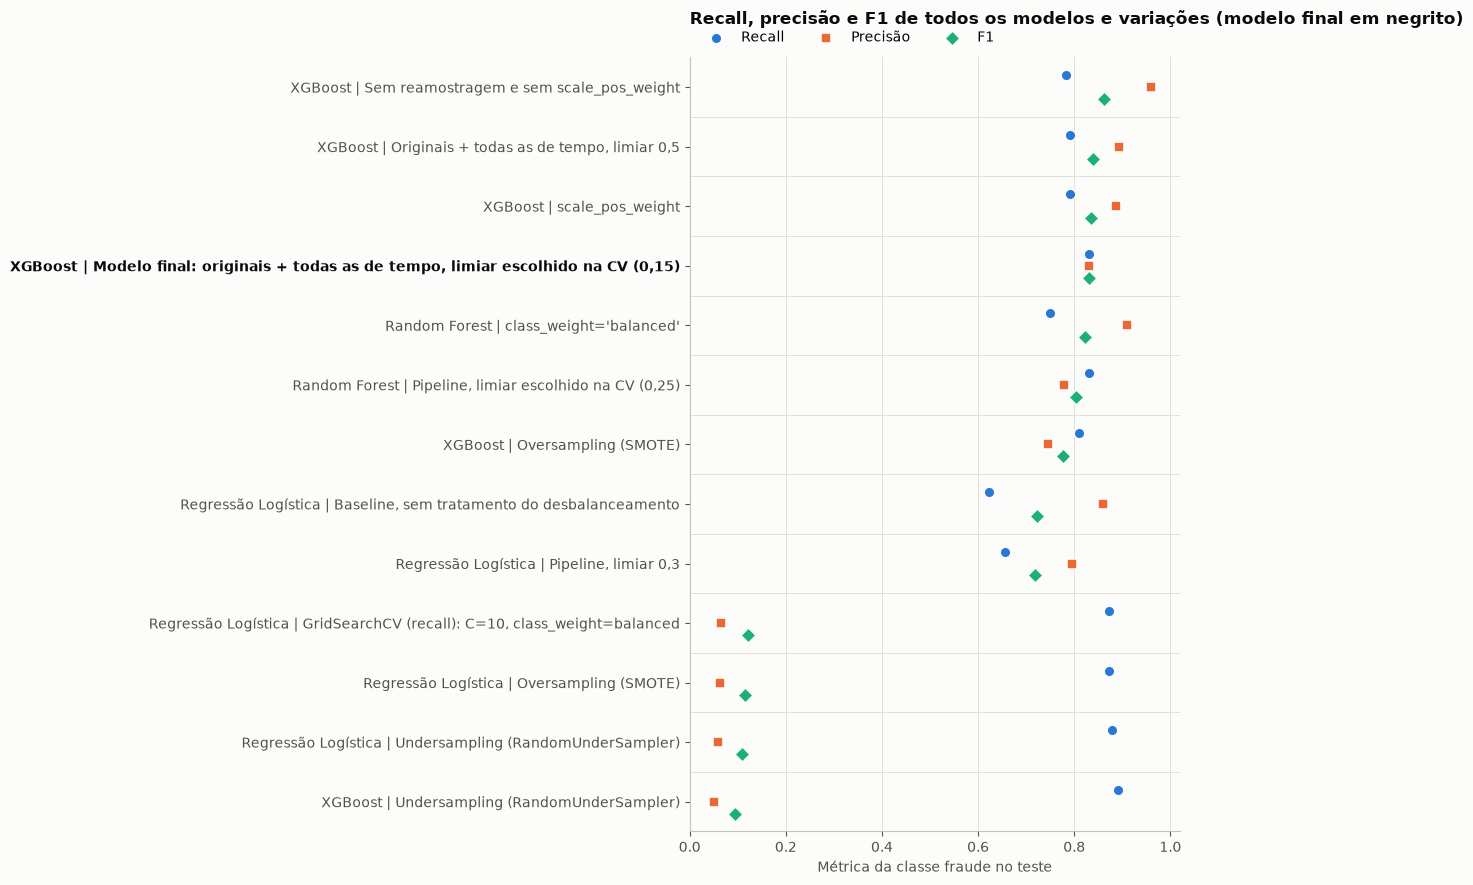

In [40]:
rotulos = tabela_final['Modelo'] + ' | ' + tabela_final['Variação']
posicoes = np.arange(len(tabela_final))

fig, ax = plt.subplots(figsize=(12, 0.55 * len(tabela_final) + 1.8))
for deslocamento, (metrica, cor, marcador) in zip([-0.2, 0, 0.2], [('Recall', AZUL, 'o'), ('Precisão', LARANJA, 's'), ('F1', AQUA, 'D')]):
    ax.scatter(tabela_final[metrica], posicoes + deslocamento, color=cor, marker=marcador, s=60, label=metrica,
               zorder=3, edgecolor=FUNDO, linewidth=1.2)
ax.set_yticks(posicoes, rotulos)
for rotulo in ax.get_yticklabels():
    if 'Modelo final' in rotulo.get_text():
        rotulo.set_fontweight('bold')
        rotulo.set_color(TINTA)
for limite in posicoes[:-1] + 0.5:
    ax.axhline(limite, color=GRADE, linewidth=0.7)
ax.set_xlim(0, 1.02)
ax.set_ylim(len(tabela_final) - 0.5, -0.5)
ax.set_xlabel('Métrica da classe fraude no teste')
ax.set_title('Recall, precisão e F1 de todos os modelos e variações (modelo final em negrito)', loc='left', pad=24)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncols=3)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

### Conclusões

1. **Acurácia não serve para este problema.** Os três modelos iniciais têm 99,9% de acurácia, inclusive a Regressão Logística, que deixa passar 38% das fraudes do teste.
2. **Modelo recomendado: XGBoost com `scale_pos_weight`, variáveis de tempo e limiar 0,15.** No teste: recall 0,831, precisão 0,831 e F1 0,831, ou seja, 123 das 148 fraudes detectadas com 25 alarmes falsos em 85.443 transações.
3. **O limiar é uma decisão de negócio.** Ele foi escolhido na validação cruzada, sem olhar o teste, com uma regra explícita (maior recall com precisão de pelo menos 80%). Se a capacidade da equipe de análise mudar, basta mudar `PRECISAO_MINIMA`.
4. **Otimizar só o recall leva a modelos inúteis.** GridSearchCV com `scoring='recall'`, undersampling e SMOTE na Regressão Logística chegam a 0,87 a 0,89 de recall, mas com precisão entre 5% e 7% e mais de 1.800 alarmes falsos.
5. **O topo da tabela por F1 não é o modelo recomendado.** O XGBoost sem peso tem o maior F1 (0,862) porque é o mais conservador (precisão 0,959), mas detecta 7 fraudes a menos que o modelo final. Como o foco do projeto é recall, o modelo final troca um pouco de precisão por mais fraudes detectadas. Os dois têm average precision parecida (0,834 e 0,842): a diferença entre eles está principalmente no ponto de corte.
6. **Reamostragem e pesos de classe deslocam o limiar, mas não melhoram a ordenação.** A average precision não sobe com SMOTE e cai com undersampling.
7. **Variáveis de tempo dão ganho pequeno, dentro do ruído.** Sem identificador de cartão, só dá para medir o comportamento do sistema inteiro.
8. **SHAP:** V4, V14, V12, V10 e V3 concentram o impacto nas previsões. A importância por ganho exagera o papel de V14 e esconde V3.

**Próximos passos:**

- Validação temporal: treinar no primeiro dia e testar no segundo, o que é mais próximo do uso real que a divisão aleatória.
- Escolher o limiar pelo custo: usar `Amount` para estimar o prejuízo evitado por fraude detectada contra o custo de cada alarme falso.
- Calibrar as probabilidades (o `scale_pos_weight` as deixa extremas) se elas forem usadas como score de risco.
- Com um identificador de cartão, criar variáveis de comportamento por cartão (frequência, valor médio, mudança de padrão).